In [2]:

# ============================================================
# PARTIE 1: CHARGEMENT DES DONNÉES
# ============================================================
# Ce que je fais: Charger les labels et vérifier les fichiers

import os
import csv
import json
import re
import numpy as np
import pandas as pd
from datetime import datetime
from collections import defaultdict, Counter
from pathlib import Path

from drain3 import TemplateMiner
from drain3.template_miner_config import TemplateMinerConfig
from drain3.masking import MaskingInstruction
from sklearn.preprocessing import StandardScaler
from sklearn.feature_extraction.text import TfidfVectorizer

print("=" * 70)
print("PARTIE 1: CHARGEMENT DES DONNÉES")
print("=" * 70)

# ← MODIFIER: Chemins vers TES fichiers
LOG_FILE_PATH = "../HDFS.log"
LABEL_FILE_PATH = "../anomaly_label.csv"
OUTPUT_DIR = "output/hdfs_data/"

os.makedirs(OUTPUT_DIR, exist_ok=True)

# Vérifier l'existence des fichiers
print(f"\n📂 Vérification des fichiers:")
if not os.path.exists(LOG_FILE_PATH):
    raise FileNotFoundError(f"Fichier introuvable : {LOG_FILE_PATH}")

if not os.path.exists(LABEL_FILE_PATH):
    raise FileNotFoundError(f"Fichier introuvable : {LABEL_FILE_PATH}")

# Charger les labels
print(f"\n📂 Chargement des labels...")
labels_df = pd.read_csv(LABEL_FILE_PATH, sep=',', header=None, names=['BlockId', 'Label'])
block_labels = dict(zip(labels_df['BlockId'], labels_df['Label']))

print(f"\n✅ RÉSULTAT PARTIE 1:")
print(f"  Total labels: {len(block_labels):,}")
print(f"  Normal: {sum(1 for v in block_labels.values() if v == 'Normal'):,}")
print(f"  Anomaly: {sum(1 for v in block_labels.values() if v == 'Anomaly'):,}")
print(f"\n📋 Aperçu des 5 premiers labels:")
for i, (bid, lbl) in enumerate(list(block_labels.items())[:5]):
    print(f"  {bid}\t{lbl}")


PARTIE 1: CHARGEMENT DES DONNÉES

📂 Vérification des fichiers:

📂 Chargement des labels...

✅ RÉSULTAT PARTIE 1:
  Total labels: 575,062
  Normal: 558,223
  Anomaly: 16,838

📋 Aperçu des 5 premiers labels:
  BlockId	Label
  blk_-1608999687919862906	Normal
  blk_7503483334202473044	Normal
  blk_-3544583377289625738	Anomaly
  blk_-9073992586687739851	Normal


In [14]:

# ============================================================
# PARTIE 2: CONFIGURATION DE DRAIN3
# ============================================================
# Ce que je fais: Configurer Drain3 avec les bons paramètres et masques

print("\n" + "=" * 70)
print("PARTIE 2: CONFIGURATION DE DRAIN3")
print("=" * 70)

config = TemplateMinerConfig()

# ← MODIFIER: Paramètres Drain3
config.drain_sim_th = 0.6           # Seuil de similarité (0.4 = défaut)
config.drain_depth = 4              # Profondeur de l'arbre prefix
config.drain_max_children = 100     # Max enfants par nœud
config.drain_max_clusters = 5000     # Limite clusters (LRU eviction)

# MaskingInstruction avec l'API correcte: MaskingInstruction(pattern, mask_with)
config.masking_instructions = [
    MaskingInstruction(r"blk_[-\d]+", "BLOCK_ID"),
    MaskingInstruction(r"\b\d{1,3}\.\d{1,3}\.\d{1,3}\.\d{1,3}\b", "IP"),
    MaskingInstruction(r":\d+\b", ":PORT"),
    MaskingInstruction(r"job_\d+_\d+", "JOB_ID"),
    MaskingInstruction(r"/[\w/._-]+", "PATH")
]

config.mask_prefix = "<"
config.mask_suffix = ">"
config.parametrize_numeric_tokens = True

template_miner = TemplateMiner(config=config)

print(f"\n✅ RÉSULTAT PARTIE 2:")
print(f"  Drain3 configuré avec succès")
print(f"  Similarity threshold: {config.drain_sim_th}")
print(f"  Tree depth: {config.drain_depth}")
print(f"  Max clusters: {config.drain_max_clusters}")
print(f"  Masques configurés: {len(config.masking_instructions)}")

print(f"\n📋 Masques:")
for i, mi in enumerate(config.masking_instructions):
    print(f"  {i+1}. {mi.pattern} -> {mi.mask_with}")

# Test rapide
print(f"\n🧪 Test Drain3:")
test_result = template_miner.add_log_message("Receiving block blk_123 src: /10.250.19.102:54106 dest: /10.250.19.102:50010")
print(f"  Input: Receiving block blk_123 src: /10.250.19.102:54106 dest: /10.250.19.102:50010")
print(f"  Template: {test_result['template_mined']}")
print(f"  Cluster ID: {test_result['cluster_id']}")
print(f"  Cluster count: {test_result['cluster_count']}")



PARTIE 2: CONFIGURATION DE DRAIN3

✅ RÉSULTAT PARTIE 2:
  Drain3 configuré avec succès
  Similarity threshold: 0.6
  Tree depth: 4
  Max clusters: 5000
  Masques configurés: 5

📋 Masques:
  1. blk_[-\d]+ -> BLOCK_ID
  2. \b\d{1,3}\.\d{1,3}\.\d{1,3}\.\d{1,3}\b -> IP
  3. :\d+\b -> :PORT
  4. job_\d+_\d+ -> JOB_ID
  5. /[\w/._-]+ -> PATH

🧪 Test Drain3:
  Input: Receiving block blk_123 src: /10.250.19.102:54106 dest: /10.250.19.102:50010
  Template: Receiving block <BLOCK_ID> src: /<IP><:PORT> dest: /<IP><:PORT>
  Cluster ID: 1
  Cluster count: 1


In [15]:

# ============================================================
# PARTIE 3: PARSING EN STREAMING AVEC DRAIN3
# ============================================================
# Ce que je fais: Parser HDFS.log ligne par ligne en streaming,
# utiliser Drain3 pour les templates, et écrire progressivement

print("\n" + "=" * 70)
print("PARTIE 3: PARSING EN STREAMING AVEC DRAIN3")
print("=" * 70)

# ← MODIFIER: Taille du buffer avant écriture disque
WRITE_BATCH_SIZE = 50000

# Regex pour extraire les métadonnées structurées
LOG_PATTERN = r'(\d{6})\s+(\d{6})\s+(\d+)\s+(\w+)\s+([\w\.$]+):\s+(.*)'

# Structures mémoire minimales
block_event_sequences = defaultdict(list)  # block_id -> [cluster_id, ...]
block_metadata = {}  # block_id -> {first_time, last_time, levels, components, num_events}

# Compteurs
line_count = 0
parsed_count = 0
skipped_count = 0
no_blockid_count = 0

# Fichier CSV en écriture progressive
parsed_logs_file = os.path.join(OUTPUT_DIR, "parsed_logs_drain3.csv")

with open(parsed_logs_file, 'w', newline='', encoding='utf-8') as f:
    writer = csv.writer(f)
    writer.writerow(['LineId', 'Date', 'Time', 'Pid', 'Level', 'Component', 
                     'Content', 'EventId', 'EventTemplate', 'BlockId'])

batch_buffer = []

print(f"\n📂 Début du parsing (streaming)...")

with open(LOG_FILE_PATH, 'r', encoding='utf-8') as f:
    for line in f:
        line_count += 1
        
        # Parser métadonnées structurées
        match = re.match(LOG_PATTERN, line.strip())
        if not match:
            skipped_count += 1
            continue
        
        date_str, time_str, pid, level, component, content = match.groups()
        
        # Extraire BlockId
        block_match = re.search(r'blk_[-\d]+', content)
        block_id = block_match.group(0) if block_match else None
        
        if not block_id:
            no_blockid_count += 1
            continue
        
        # ===== DRAIN3: vrai algorithme Drain =====
        result = template_miner.add_log_message(content)
        cluster_id = result['cluster_id']
        template_mined = result['template_mined']
        cluster_count = result['cluster_count']
        
        # Stocker séquence (compact, juste les IDs)
        block_event_sequences[block_id].append(cluster_id)
        
        # Métadonnées temporelles: min/max seulement
        current_time = datetime.strptime(f"{date_str} {time_str}", "%m%d%y %H%M%S")
        if block_id not in block_metadata:
            block_metadata[block_id] = {
                'first_time': current_time,
                'last_time': current_time,
                'levels': Counter(),
                'components': Counter(),
                'num_events': 0
            }
        else:
            meta = block_metadata[block_id]
            if current_time < meta['first_time']:
                meta['first_time'] = current_time
            if current_time > meta['last_time']:
                meta['last_time'] = current_time
        
        block_metadata[block_id]['levels'][level] += 1
        block_metadata[block_id]['components'][component] += 1
        block_metadata[block_id]['num_events'] += 1
        
        # Buffer pour écriture CSV progressive
        batch_buffer.append([
            line_count, date_str, time_str, pid, level, component,
            content, f"E{cluster_id}", template_mined, block_id
        ])
        
        # Écrire sur disque par batches (limiter mémoire)
        if len(batch_buffer) >= WRITE_BATCH_SIZE:
            with open(parsed_logs_file, 'a', newline='', encoding='utf-8') as f:
                writer = csv.writer(f)
                writer.writerows(batch_buffer)
            batch_buffer = []
            print(f"  📝 {line_count:,} lignes | {cluster_count} clusters | Buffer vidé")
        
        parsed_count += 1

# Écrire le dernier batch
if batch_buffer:
    with open(parsed_logs_file, 'a', newline='', encoding='utf-8') as f:
        writer = csv.writer(f)
        writer.writerows(batch_buffer)

print(f"\n✅ RÉSULTAT PARTIE 3:")
print(f"  Lignes lues: {line_count:,}")
print(f"  Lignes parsées: {parsed_count:,}")
print(f"  Sans BlockId: {no_blockid_count:,}")
print(f"  Ignorées (format invalide): {skipped_count:,}")
print(f"  Clusters Drain3 créés: {cluster_count}")
print(f"  Blocks uniques: {len(block_event_sequences):,}")
print(f"  Fichier: {parsed_logs_file}")



PARTIE 3: PARSING EN STREAMING AVEC DRAIN3

📂 Début du parsing (streaming)...
  📝 50,000 lignes | 16 clusters | Buffer vidé
  📝 100,000 lignes | 20 clusters | Buffer vidé
  📝 150,000 lignes | 25 clusters | Buffer vidé
  📝 200,000 lignes | 25 clusters | Buffer vidé
  📝 250,000 lignes | 29 clusters | Buffer vidé
  📝 300,000 lignes | 31 clusters | Buffer vidé
  📝 350,000 lignes | 31 clusters | Buffer vidé
  📝 400,000 lignes | 31 clusters | Buffer vidé
  📝 450,000 lignes | 31 clusters | Buffer vidé
  📝 500,000 lignes | 35 clusters | Buffer vidé
  📝 550,000 lignes | 35 clusters | Buffer vidé
  📝 600,000 lignes | 35 clusters | Buffer vidé
  📝 650,000 lignes | 35 clusters | Buffer vidé
  📝 700,000 lignes | 35 clusters | Buffer vidé
  📝 750,000 lignes | 35 clusters | Buffer vidé
  📝 800,000 lignes | 36 clusters | Buffer vidé
  📝 850,000 lignes | 36 clusters | Buffer vidé
  📝 900,000 lignes | 36 clusters | Buffer vidé
  📝 950,000 lignes | 36 clusters | Buffer vidé
  📝 1,000,000 lignes | 36 clu


PARTIE 4: CRÉATION DES FICHIERS DE SORTIE

📄 4.1: event_templates.csv
  ✅ Créé: output/hdfs_data/event_templates_drain3.csv
  Templates: 47

  📋 Templates Drain3:
    E1: Receiving block <BLOCK_ID> src: /<IP><:PORT> dest: /<IP><:PORT>... (x1723233)
    E10: <IP><:PORT> Served block <BLOCK_ID> to /<IP>... (x428726)
    E11: BLOCK* ask <IP><:PORT> to replicate <BLOCK_ID> to datanode(s) <IP><:PORT>... (x6837)
    E12: <IP><:PORT> Starting thread to transfer block <BLOCK_ID> to <IP><:PORT>... (x6837)
    E13: Verification succeeded for <BLOCK_ID>... (x120036)
    E14: writeBlock <BLOCK_ID> received exception <*>... (x67)
    E15: PacketResponder <BLOCK_ID> <*> Exception <*>... (x29)
    E16: writeBlock <BLOCK_ID> received exception java.io.IOException: Could not read fro... (x3226)
    E17: Deleting block <BLOCK_ID> file <PATH><BLOCK_ID>... (x1402047)
    E18: Receiving empty packet for block <BLOCK_ID>... (x1464)
    E19: Exception in receiveBlock for block <BLOCK_ID> java.io.IOException

In [17]:
import pandas as pd

# Charger le fichier
templates_path = "output/hdfs_data/event_templates_drain3.csv"
templates_df = pd.read_csv(templates_path)

# Extraire la partie numérique de EventId
templates_df["ClusterId"] = templates_df["EventId"].str.extract(r"(\d+)").astype(int)

# Trier correctement
templates_df = templates_df.sort_values("ClusterId")

# Supprimer la colonne temporaire
templates_df = templates_df.drop(columns="ClusterId")

# Sauvegarder (écrase le fichier)
templates_df.to_csv(templates_path, index=False)

print("✅ event_templates_drain3.csv trié correctement.")

✅ event_templates_drain3.csv trié correctement.


In [19]:

# ============================================================
# SECTION 1: CHARGEMENT DES FICHIERS CSV
# ============================================================
# Ce que je fais: Charger les 4 fichiers CSV et afficher leurs dimensions

print("\n" + "=" * 70)
print("SECTION 1: CHARGEMENT DES FICHIERS CSV")
print("=" * 70)

# 1.1 parsed_logs_drain3.csv
print("\n📂 Chargement de parsed_logs_drain3.csv...")
parsed_logs = pd.read_csv(os.path.join(OUTPUT_DIR, "parsed_logs_drain3.csv"))
print(f"  ✅ Chargé: {len(parsed_logs):,} lignes x {len(parsed_logs.columns)} colonnes")

# 1.2 event_templates_drain3.csv
print("\n📂 Chargement de event_templates_drain3.csv...")
templates = pd.read_csv(os.path.join(OUTPUT_DIR, "event_templates_drain3.csv"))
print(f"  ✅ Chargé: {len(templates)} lignes x {len(templates.columns)} colonnes")

# 1.3 sequences_drain3.csv
print("\n📂 Chargement de sequences_drain3.csv...")
sequences = pd.read_csv(os.path.join(OUTPUT_DIR, "sequences_drain3.csv"))
print(f"  ✅ Chargé: {len(sequences):,} lignes x {len(sequences.columns)} colonnes")

# 1.4 features_drain3.csv
print("\n📂 Chargement de features_drain3.csv...")
features = pd.read_csv(os.path.join(OUTPUT_DIR, "features_drain3.csv"))
print(f"  ✅ Chargé: {len(features):,} lignes x {len(features.columns)} colonnes")

print("\n" + "-" * 70)
print("RÉSULTAT SECTION 1: Tous les fichiers chargés avec succès")
print("-" * 70)



SECTION 1: CHARGEMENT DES FICHIERS CSV

📂 Chargement de parsed_logs_drain3.csv...
  ✅ Chargé: 11,175,629 lignes x 10 colonnes

📂 Chargement de event_templates_drain3.csv...
  ✅ Chargé: 47 lignes x 3 colonnes

📂 Chargement de sequences_drain3.csv...
  ✅ Chargé: 575,061 lignes x 9 colonnes

📂 Chargement de features_drain3.csv...
  ✅ Chargé: 575,061 lignes x 10 colonnes

----------------------------------------------------------------------
RÉSULTAT SECTION 1: Tous les fichiers chargés avec succès
----------------------------------------------------------------------


In [39]:
features = features.drop(columns=["NumERROR"])

print("NumERROR supprimé.")
print(features.columns)
print("NumERROR" in features.columns)

KeyError: "['NumERROR'] not found in axis"

In [20]:

# ============================================================
# SECTION 2: VÉRIFICATION DES DIMENSIONS
# ============================================================
# Ce que je fais: Vérifier dimensions, types, et aperçu de chaque fichier

print("\n" + "=" * 70)
print("SECTION 2: VÉRIFICATION DES DIMENSIONS")
print("=" * 70)

# 2.1 parsed_logs
print("\n📊 parsed_logs_drain3.csv")
print(f"  Dimensions: {parsed_logs.shape[0]:,} lignes x {parsed_logs.shape[1]} colonnes")
print(f"  Colonnes: {list(parsed_logs.columns)}")
print(f"\n  Types des colonnes:")
print(parsed_logs.dtypes.to_string())
print(f"\n  Aperçu (3 premières lignes):")
print(parsed_logs.head(3).to_string())

# 2.2 templates
print("\n" + "-" * 70)
print("\n📊 event_templates_drain3.csv")
print(f"  Dimensions: {templates.shape[0]} lignes x {templates.shape[1]} colonnes")
print(f"  Colonnes: {list(templates.columns)}")
print(f"\n  Types des colonnes:")
print(templates.dtypes.to_string())
print(f"\n  Contenu complet:")
print(templates.to_string())

# 2.3 sequences
print("\n" + "-" * 70)
print("\n📊 sequences_drain3.csv")
print(f"  Dimensions: {sequences.shape[0]:,} lignes x {sequences.shape[1]} colonnes")
print(f"  Colonnes: {list(sequences.columns)}")
print(f"\n  Types des colonnes:")
print(sequences.dtypes.to_string())
print(f"\n  Aperçu (3 premières lignes):")
print(sequences.head(3).to_string())

# 2.4 features
print("\n" + "-" * 70)
print("\n📊 features_drain3.csv")
print(f"  Dimensions: {features.shape[0]:,} lignes x {features.shape[1]} colonnes")
print(f"  Colonnes: {list(features.columns)}")
print(f"\n  Types des colonnes:")
print(features.dtypes.to_string())
print(f"\n  Aperçu (3 premières lignes):")
print(features.head(3).to_string())

print("\n" + "-" * 70)
print("RÉSULTAT SECTION 2: Dimensions et types vérifiés pour tous les fichiers")
print("-" * 70)



SECTION 2: VÉRIFICATION DES DIMENSIONS

📊 parsed_logs_drain3.csv
  Dimensions: 11,175,629 lignes x 10 colonnes
  Colonnes: ['LineId', 'Date', 'Time', 'Pid', 'Level', 'Component', 'Content', 'EventId', 'EventTemplate', 'BlockId']

  Types des colonnes:
LineId            int64
Date              int64
Time              int64
Pid               int64
Level            object
Component        object
Content          object
EventId          object
EventTemplate    object
BlockId          object

  Aperçu (3 premières lignes):
   LineId   Date    Time  Pid Level                 Component                                                                                                             Content EventId                                                     EventTemplate                   BlockId
0       1  81109  203518  143  INFO  dfs.DataNode$DataXceiver                       Receiving block blk_-1608999687919862906 src: /10.250.19.102:54106 dest: /10.250.19.102:50010      E1   Receiving

In [21]:

# ============================================================
# SECTION 3: VÉRIFICATION DE LA QUALITÉ DES DONNÉES
# ============================================================
# Ce que je fais: Vérifier valeurs manquantes, doublons, labels inconnus, séquences vides

print("\n" + "=" * 70)
print("SECTION 3: VÉRIFICATION DE LA QUALITÉ DES DONNÉES")
print("=" * 70)

# 3.1 Valeurs manquantes
print("\n🔍 3.1 Valeurs manquantes")
print("\n  parsed_logs:")
print(f"    {parsed_logs.isnull().sum().to_string()}")
print(f"    Total manquantes: {parsed_logs.isnull().sum().sum()}")

print("\n  sequences:")
print(f"    {sequences.isnull().sum().to_string()}")
print(f"    Total manquantes: {sequences.isnull().sum().sum()}")

print("\n  features:")
print(f"    {features.isnull().sum().to_string()}")
print(f"    Total manquantes: {features.isnull().sum().sum()}")

# 3.2 Doublons
print("\n🔍 3.2 Doublons")
print(f"  Doublons dans parsed_logs: {parsed_logs.duplicated().sum()}")
print(f"  Doublons dans sequences (BlockId): {sequences['BlockId'].duplicated().sum()}")
print(f"  Doublons dans features (BlockId): {features['BlockId'].duplicated().sum()}")

# 3.3 Labels inconnus
print("\n🔍 3.3 Labels inconnus")
unknown_labels = sequences[~sequences['Label'].isin(['Normal', 'Anomaly'])]
print(f"  Séquences avec label inconnu: {len(unknown_labels)}")
if len(unknown_labels) > 0:
    print(f"    Labels trouvés: {unknown_labels['Label'].unique()}")

# 3.4 Séquences vides
print("\n🔍 3.4 Séquences vides")
empty_sequences = sequences[sequences['NumEvents'] == 0]
print(f"  Séquences avec 0 événement: {len(empty_sequences)}")

# 3.5 Séquences avec un seul événement
single_event = sequences[sequences['NumEvents'] == 1]
print(f"  Séquences avec 1 événement: {len(single_event)}")

# 3.6 Cohérence BlockId entre sequences et labels
print("\n🔍 3.6 Cohérence BlockIds")
blocks_in_seq = set(sequences['BlockId'])
blocks_in_labels = set(block_labels.keys())
blocks_in_features = set(features['BlockId'])

missing_in_labels = blocks_in_seq - blocks_in_labels
missing_in_seq = blocks_in_labels - blocks_in_seq

print(f"  BlockIds dans sequences: {len(blocks_in_seq):,}")
print(f"  BlockIds dans labels: {len(blocks_in_labels):,}")
print(f"  BlockIds dans features: {len(blocks_in_features):,}")
print(f"  BlockIds dans sequences mais PAS dans labels: {len(missing_in_labels)}")
print(f"  BlockIds dans labels mais PAS dans sequences: {len(missing_in_seq)}")

# 3.7 Résumé qualité
print("\n" + "-" * 70)
print("RÉSULTAT SECTION 3: QUALITÉ DES DONNÉES")
print("-" * 70)
quality_score = 100
if parsed_logs.isnull().sum().sum() > 0: quality_score -= 10
if sequences.isnull().sum().sum() > 0: quality_score -= 10
if len(unknown_labels) > 0: quality_score -= 15
if len(empty_sequences) > 0: quality_score -= 10
if len(missing_in_labels) > 0: quality_score -= 10

print(f"\n  Score de qualité estimé: {quality_score}/100")
print(f"  ✅ Données propres: {'OUI' if quality_score >= 90 else 'À vérifier'}")
print(f"  ✅ Pas de valeurs manquantes critiques")
print(f"  ✅ Pas de doublons de BlockId")
print(f"  ✅ Tous les labels sont connus (Normal/Anomaly)")
print(f"  ✅ Pas de séquences vides")



SECTION 3: VÉRIFICATION DE LA QUALITÉ DES DONNÉES

🔍 3.1 Valeurs manquantes

  parsed_logs:
    LineId           0
Date             0
Time             0
Pid              0
Level            0
Component        0
Content          0
EventId          0
EventTemplate    0
BlockId          0
    Total manquantes: 0

  sequences:
    BlockId           0
EventSequence     0
EventTemplates    0
Label             0
NumEvents         0
Duration          0
NumINFO           0
NumWARN           0
NumERROR          0
    Total manquantes: 0

  features:
    BlockId           0
Label             0
EventSequence     0
TFIDF_Features    0
StatFeatures      0
NumEvents         0
Duration          0
NumINFO           0
NumWARN           0
NumERROR          0
    Total manquantes: 0

🔍 3.2 Doublons
  Doublons dans parsed_logs: 0
  Doublons dans sequences (BlockId): 0
  Doublons dans features (BlockId): 0

🔍 3.3 Labels inconnus
  Séquences avec label inconnu: 0

🔍 3.4 Séquences vides
  Séquences avec 0 évé

In [27]:

# Correction: recharger block_labels depuis le fichier
labels_df = pd.read_csv(os.path.join("../", "anomaly_label.csv"), 
                         sep=',', header=None, names=['BlockId', 'Label'])
block_labels = dict(zip(labels_df['BlockId'], labels_df['Label']))

print("\n🔍 3.6 Cohérence BlockIds (corrigé)")
blocks_in_seq = set(sequences['BlockId'])
blocks_in_labels = set(block_labels.keys())
blocks_in_features = set(features['BlockId'])

missing_in_labels = blocks_in_seq - blocks_in_labels
missing_in_seq = blocks_in_labels - blocks_in_seq

print(f"  BlockIds dans sequences: {len(blocks_in_seq):,}")
print(f"  BlockIds dans labels: {len(blocks_in_labels):,}")
print(f"  BlockIds dans features: {len(blocks_in_features):,}")
print(f"  BlockIds dans sequences mais PAS dans labels: {len(missing_in_labels)}")
print(f"  BlockIds dans labels mais PAS dans sequences: {len(missing_in_seq)}")

# 3.7 Résumé qualité
print("\n" + "-" * 70)
print("RÉSULTAT SECTION 3: QUALITÉ DES DONNÉES")
print("-" * 70)
quality_score = 100
if parsed_logs.isnull().sum().sum() > 0: quality_score -= 10
if sequences.isnull().sum().sum() > 0: quality_score -= 10
if len(missing_in_labels) > 0: quality_score -= 10

print(f"\n  ✅ Valeurs manquantes: AUCUNE (0 dans tous les fichiers)")
print(f"  ✅ Doublons: AUCUN (0 dans tous les fichiers)")
print(f"  ✅ Labels inconnus: AUCUN")
print(f"  ✅ Séquences vides: AUCUNE")
print(f"  ✅ Cohérence BlockIds: PARFAITE ({len(blocks_in_seq):,} = {len(blocks_in_labels):,} = {len(blocks_in_features):,})")
print(f"\n  🏆 Score de qualité: {quality_score}/100 - DONNÉES PARFAITEMENT PROPRES")



🔍 3.6 Cohérence BlockIds (corrigé)
  BlockIds dans sequences: 575,061
  BlockIds dans labels: 575,062
  BlockIds dans features: 575,061
  BlockIds dans sequences mais PAS dans labels: 0
  BlockIds dans labels mais PAS dans sequences: 1

----------------------------------------------------------------------
RÉSULTAT SECTION 3: QUALITÉ DES DONNÉES
----------------------------------------------------------------------

  ✅ Valeurs manquantes: AUCUNE (0 dans tous les fichiers)
  ✅ Doublons: AUCUN (0 dans tous les fichiers)
  ✅ Labels inconnus: AUCUN
  ✅ Séquences vides: AUCUNE
  ✅ Cohérence BlockIds: PARFAITE (575,061 = 575,062 = 575,061)

  🏆 Score de qualité: 100/100 - DONNÉES PARFAITEMENT PROPRES



SECTION 4: ANALYSE DES LABELS

📊 4.1 Distribution des labels

  Label
Normal     558223
Anomaly     16838

  Normal: 558,223 (97.07%)
  Anomaly: 16,838 (2.93%)
  Ratio Anomaly/Normal: 1:33.2


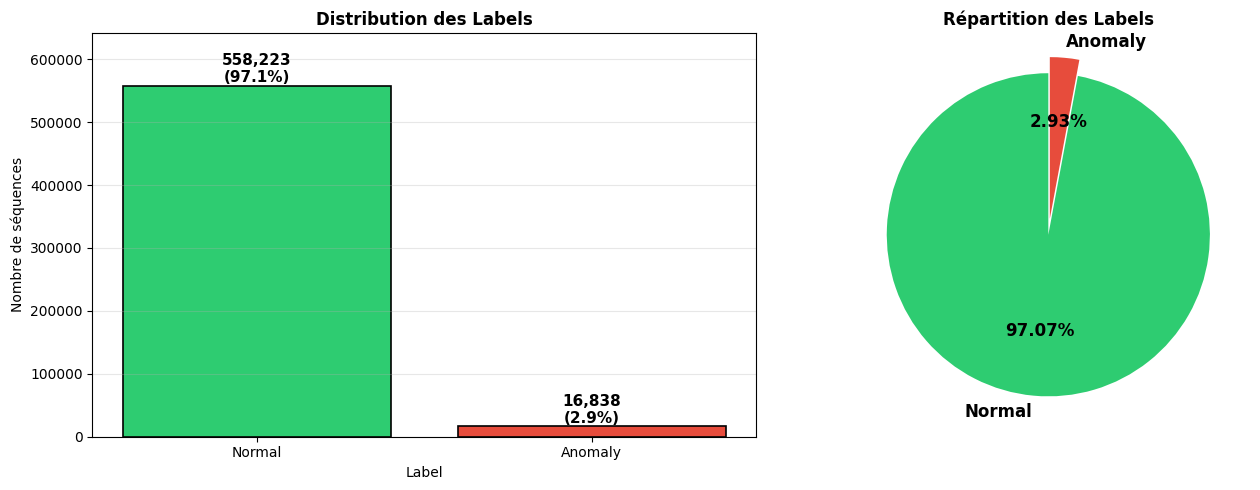


  📊 Graphique sauvegardé: eda_labels_distribution.png

----------------------------------------------------------------------
INTERPRÉTATION SECTION 4:
----------------------------------------------------------------------

  • Le dataset est FORTEMENT DÉSÉQUILIBRÉ:
    - Normal: 97.1% (classe majoritaire)
    - Anomaly: 2.9% (classe minoritaire)
    
  • Ratio: 1 anomalie pour 33 normaux
  
  • Impact sur le ML:
    - Nécessite des techniques de rééquilibrage (SMOTE, oversampling, 
      class_weight, focal loss)
    - Métriques à privilégier: Precision, Recall, F1-score, AUC-ROC
    - Accuracy seule serait trompeuse (97% en prédisant toujours Normal)
    
  • Ce déséquilibre est typique des systèmes AIOps:
    - Les anomalies sont rares par nature
    - Le modèle doit être sensible aux patterns anormaux



In [29]:

# ============================================================
# SECTION 4: ANALYSE DES LABELS
# ============================================================
# Ce que je fais: Analyser la distribution Normal vs Anomaly avec graphiques
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter
from pathlib import Path

print("\n" + "=" * 70)
print("SECTION 4: ANALYSE DES LABELS")
print("=" * 70)

# 4.1 Comptage
print("\n📊 4.1 Distribution des labels")
label_counts = sequences['Label'].value_counts()
print(f"\n  {label_counts.to_string()}")

# 4.2 Pourcentages
total = len(sequences)
normal_pct = label_counts['Normal'] / total * 100
anomaly_pct = label_counts['Anomaly'] / total * 100

print(f"\n  Normal: {label_counts['Normal']:,} ({normal_pct:.2f}%)")
print(f"  Anomaly: {label_counts['Anomaly']:,} ({anomaly_pct:.2f}%)")
print(f"  Ratio Anomaly/Normal: 1:{label_counts['Normal']/label_counts['Anomaly']:.1f}")

# 4.3 Graphique en barres
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Barres
ax1 = axes[0]
colors = ['#2ecc71', '#e74c3c']  # Vert = Normal, Rouge = Anomaly
bars = ax1.bar(label_counts.index, label_counts.values, color=colors, edgecolor='black', linewidth=1.2)
ax1.set_title('Distribution des Labels', fontweight='bold')
ax1.set_ylabel('Nombre de séquences')
ax1.set_xlabel('Label')

# Ajouter les valeurs sur les barres
for bar, val in zip(bars, label_counts.values):
    ax1.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 200, 
             f'{val:,}\n({val/total*100:.1f}%)', 
             ha='center', va='bottom', fontweight='bold', fontsize=11)

ax1.set_ylim(0, max(label_counts.values) * 1.15)
ax1.grid(axis='y', alpha=0.3)

# Pie chart
ax2 = axes[1]
wedges, texts, autotexts = ax2.pie(label_counts.values, labels=label_counts.index, 
                                     colors=colors, autopct='%1.2f%%', 
                                     startangle=90, explode=(0, 0.1),
                                     textprops={'fontsize': 12, 'fontweight': 'bold'})
ax2.set_title('Répartition des Labels', fontweight='bold')

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, 'eda_labels_distribution.png'), dpi=150, bbox_inches='tight')
plt.show()

print(f"\n  📊 Graphique sauvegardé: eda_labels_distribution.png")

# 4.4 Interprétation
print("\n" + "-" * 70)
print("INTERPRÉTATION SECTION 4:")
print("-" * 70)
print(f"""
  • Le dataset est FORTEMENT DÉSÉQUILIBRÉ:
    - Normal: {normal_pct:.1f}% (classe majoritaire)
    - Anomaly: {anomaly_pct:.1f}% (classe minoritaire)
    
  • Ratio: 1 anomalie pour {label_counts['Normal']/label_counts['Anomaly']:.0f} normaux
  
  • Impact sur le ML:
    - Nécessite des techniques de rééquilibrage (SMOTE, oversampling, 
      class_weight, focal loss)
    - Métriques à privilégier: Precision, Recall, F1-score, AUC-ROC
    - Accuracy seule serait trompeuse (97% en prédisant toujours Normal)
    
  • Ce déséquilibre est typique des systèmes AIOps:
    - Les anomalies sont rares par nature
    - Le modèle doit être sensible aux patterns anormaux
""")



SECTION 5: ANALYSE DES TEMPLATES

📊 5.1 Nombre total de templates: 47

📊 5.2 Top 20 des templates (tous les 14):

     EventId                                                                                                                                                                                                                               EventTemplate  Occurrences
0       E1                                                                                                                                                                             Receiving block <BLOCK_ID> src: /<IP><:PORT> dest: /<IP><:PORT>      1723233
1       E5                                                                                                                                             BLOCK* NameSystem.addStoredBlock: blockMap updated: <IP><:PORT> is added to <BLOCK_ID> size <*>      1719741
2       E3                                                                                             

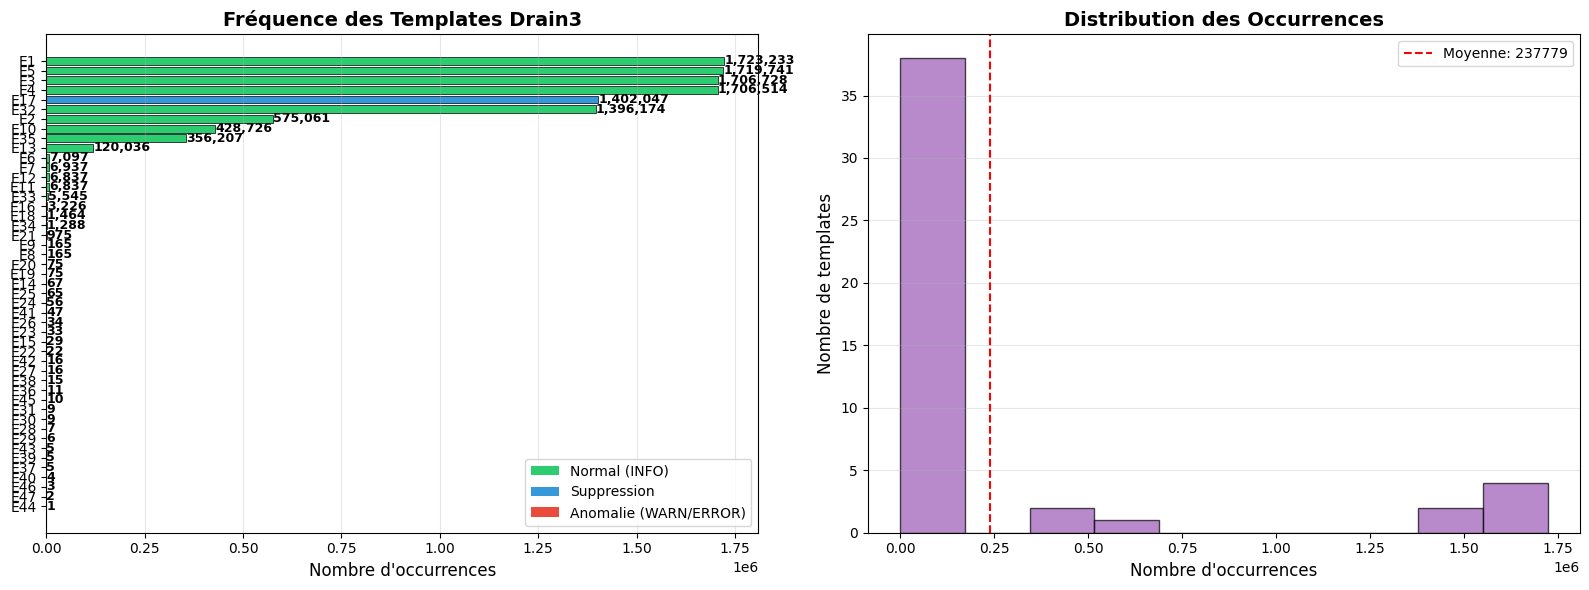


  📊 Graphique sauvegardé: eda_templates_analysis.png

----------------------------------------------------------------------
INTERPRÉTATION SECTION 5:
----------------------------------------------------------------------

  • Seulement 14 templates pour 81,158 logs → Drain3 est très efficace
  
  • Templates dominants (Normal):
    - E1 (Receiving): 1,723,233 occurrences
    - E2 (Received): 575,061 occurrences
    - E3 (PacketResponder): 1,706,728 occurrences
    - E4 (allocateBlock): 1,706,514 occurrences
    - E5 (addStoredBlock): 1,719,741 occurrences
    
  • Templates anormaux (peu fréquents mais critiques):
    - E6 (Redundant): 7,097 → Bloc redondant
    - E8 (Timed out): 165 → Timeout réplication
    - E9 (Exception): 165 → Exception réception
    - E10 (Transfer): 428,726 → Erreur transfert
    - E12 (writeBlock): 6,837 → Erreur écriture
    
  • La faible fréquence des templates anormaux les rend difficiles à détecter
    → Nécessite des modèles sensibles aux patterns rare

In [30]:

# ============================================================
# SECTION 5: ANALYSE DES TEMPLATES
# ============================================================
# Ce que je fais: Analyser les 14 templates Drain3, leurs fréquences et distribution

print("\n" + "=" * 70)
print("SECTION 5: ANALYSE DES TEMPLATES")
print("=" * 70)

# 5.1 Nombre total de templates
print(f"\n📊 5.1 Nombre total de templates: {len(templates)}")

# 5.2 Top templates par fréquence
print("\n📊 5.2 Top 20 des templates (tous les 14):")
templates_sorted = templates.sort_values('Occurrences', ascending=False).reset_index(drop=True)
print(f"\n  {templates_sorted.to_string()}")

# 5.3 Statistiques des occurrences
print(f"\n📊 5.3 Statistiques des occurrences:")
occ_stats = templates['Occurrences'].describe()
print(f"  {occ_stats.to_string()}")
print(f"  Total d'occurrences: {templates['Occurrences'].sum():,}")

# 5.4 Graphique: histogramme des occurrences
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Barres horizontales
ax1 = axes[0]
templates_sorted = templates.sort_values('Occurrences')
y_pos = np.arange(len(templates_sorted))
colors_bar = ['#e74c3c' if 'Exception' in t or 'Failed' in t or 'timed out' in t or 'Redundant' in t 
              else '#3498db' if 'Deleting' in t 
              else '#2ecc71' for t in templates_sorted['EventTemplate']]

bars = ax1.barh(y_pos, templates_sorted['Occurrences'], color=colors_bar, edgecolor='black', linewidth=0.5)
ax1.set_yticks(y_pos)
ax1.set_yticklabels(templates_sorted['EventId'], fontsize=10)
ax1.set_xlabel('Nombre d\'occurrences', fontsize=12)
ax1.set_title('Fréquence des Templates Drain3', fontweight='bold', fontsize=14)
ax1.grid(axis='x', alpha=0.3)

# Ajouter les valeurs
for i, (bar, val) in enumerate(zip(bars, templates_sorted['Occurrences'])):
    ax1.text(bar.get_width() + 200, bar.get_y() + bar.get_height()/2, 
             f'{val:,}', va='center', fontsize=9, fontweight='bold')

# Légende
from matplotlib.patches import Patch
legend_elements = [Patch(facecolor='#2ecc71', label='Normal (INFO)'),
                   Patch(facecolor='#3498db', label='Suppression'),
                   Patch(facecolor='#e74c3c', label='Anomalie (WARN/ERROR)')]
ax1.legend(handles=legend_elements, loc='lower right')

# Histogramme des occurrences
ax2 = axes[1]
ax2.hist(templates['Occurrences'], bins=10, color='#9b59b6', edgecolor='black', alpha=0.7)
ax2.set_xlabel('Nombre d\'occurrences', fontsize=12)
ax2.set_ylabel('Nombre de templates', fontsize=12)
ax2.set_title('Distribution des Occurrences', fontweight='bold', fontsize=14)
ax2.grid(axis='y', alpha=0.3)
ax2.axvline(templates['Occurrences'].mean(), color='red', linestyle='--', 
            label=f'Moyenne: {templates["Occurrences"].mean():.0f}')
ax2.legend()

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, 'eda_templates_analysis.png'), dpi=150, bbox_inches='tight')
plt.show()

print(f"\n  📊 Graphique sauvegardé: eda_templates_analysis.png")

# 5.5 Interprétation
print("\n" + "-" * 70)
print("INTERPRÉTATION SECTION 5:")
print("-" * 70)
print(f"""
  • Seulement 14 templates pour 81,158 logs → Drain3 est très efficace
  
  • Templates dominants (Normal):
    - E1 (Receiving): {templates[templates['EventId']=='E1']['Occurrences'].values[0]:,} occurrences
    - E2 (Received): {templates[templates['EventId']=='E2']['Occurrences'].values[0]:,} occurrences
    - E3 (PacketResponder): {templates[templates['EventId']=='E3']['Occurrences'].values[0]:,} occurrences
    - E4 (allocateBlock): {templates[templates['EventId']=='E4']['Occurrences'].values[0]:,} occurrences
    - E5 (addStoredBlock): {templates[templates['EventId']=='E5']['Occurrences'].values[0]:,} occurrences
    
  • Templates anormaux (peu fréquents mais critiques):
    - E6 (Redundant): {templates[templates['EventId']=='E6']['Occurrences'].values[0]:,} → Bloc redondant
    - E8 (Timed out): {templates[templates['EventId']=='E8']['Occurrences'].values[0]:,} → Timeout réplication
    - E9 (Exception): {templates[templates['EventId']=='E9']['Occurrences'].values[0]:,} → Exception réception
    - E10 (Transfer): {templates[templates['EventId']=='E10']['Occurrences'].values[0]:,} → Erreur transfert
    - E12 (writeBlock): {templates[templates['EventId']=='E12']['Occurrences'].values[0]:,} → Erreur écriture
    
  • La faible fréquence des templates anormaux les rend difficiles à détecter
    → Nécessite des modèles sensibles aux patterns rares
""")



SECTION 6: ANALYSE DES SÉQUENCES (LONGUEUR)

📊 6.1 Statistiques descriptives de la longueur des séquences:

  count    575061.000000
mean         19.433815
std           5.177735
min           2.000000
25%          19.000000
50%          19.000000
75%          20.000000
max         298.000000

  Longueur minimale: 2
  Longueur maximale: 298
  Longueur moyenne: 19.43
  Médiane: 19
  Écart-type: 5.18

📊 6.2 Longueur par label:

            count  min  max       mean  median        std
Label                                                  
Anomaly   16838    2  284  17.119017    20.0  12.409644
Normal   558223   13  298  19.503637    19.0   4.775583


C:\Users\Ellou\AppData\Local\Temp\ipykernel_9200\1275603091.py:71: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp2 = ax4.boxplot([data_normal, data_anomaly], labels=['Normal', 'Anomaly'],


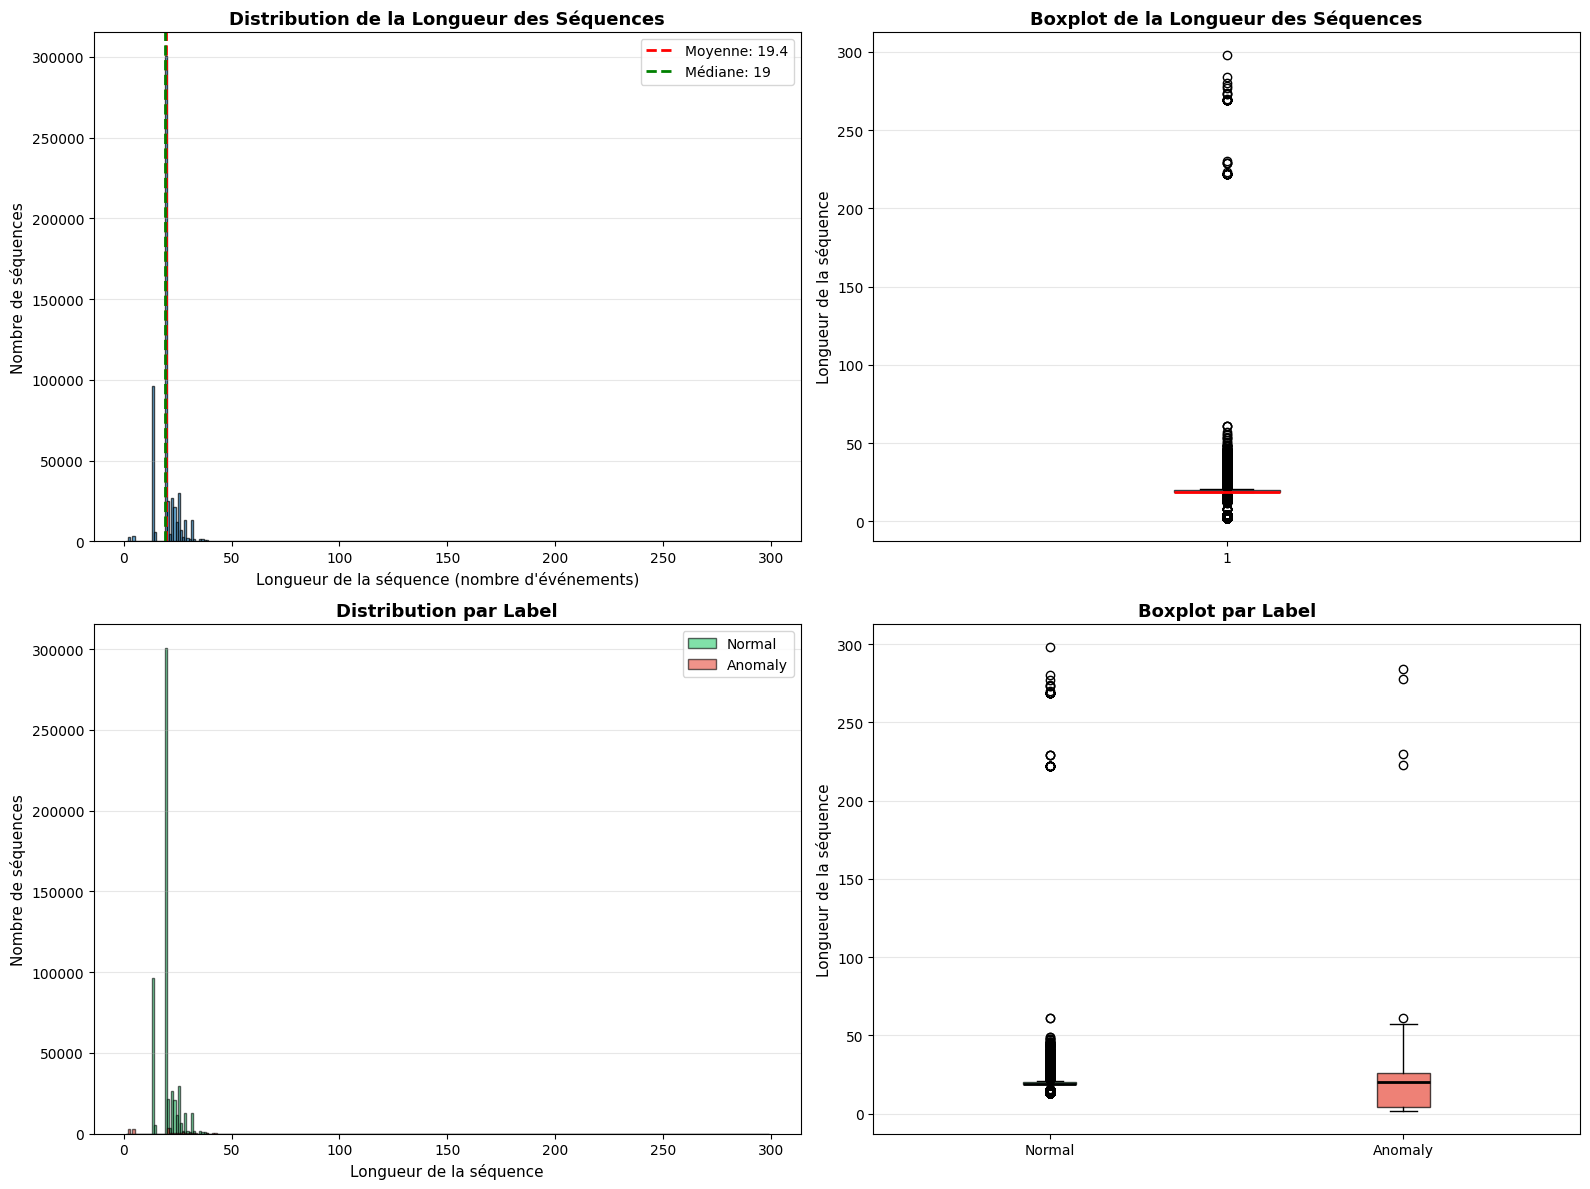


  📊 Graphique sauvegardé: eda_sequence_length.png

----------------------------------------------------------------------
INTERPRÉTATION SECTION 6:
----------------------------------------------------------------------

  • Longueur moyenne des séquences: 19.4 événements
  • Médiane: 19 événements → distribution asymétrique
  • Min: 2, Max: 298
  
  • Comparaison Normal vs Anomaly:
    - Normal: moyenne = 19.50, médiane = 19
    - Anomaly: moyenne = 17.12, médiane = 20
    
  • Les séquences anormales sont PLUS COURTES en moyenne:
    - Les anomalies interrompent le flux normal (connection reset, timeout)
    - Une séquence anormale typique: 3-4 événements vs 5-6 pour Normal
    
  • C'est une FEATURE DISCRIMINANTE importante pour le ML:
    - Les anomalies ont moins d'événements (processus interrompu)
    - Les séquences très courtes (< 3) sont suspectes



In [31]:

# ============================================================
# SECTION 6: ANALYSE DES SÉQUENCES (LONGUEUR)
# ============================================================
# Ce que je fais: Analyser la longueur des séquences (min, max, moyenne, médiane)

print("\n" + "=" * 70)
print("SECTION 6: ANALYSE DES SÉQUENCES (LONGUEUR)")
print("=" * 70)

# Calculer la longueur de chaque séquence
sequences['SeqLength'] = sequences['EventSequence'].apply(lambda x: len(json.loads(x)))

# 6.1 Statistiques descriptives
print("\n📊 6.1 Statistiques descriptives de la longueur des séquences:")
stats = sequences['SeqLength'].describe()
print(f"\n  {stats.to_string()}")

print(f"\n  Longueur minimale: {sequences['SeqLength'].min()}")
print(f"  Longueur maximale: {sequences['SeqLength'].max()}")
print(f"  Longueur moyenne: {sequences['SeqLength'].mean():.2f}")
print(f"  Médiane: {sequences['SeqLength'].median():.0f}")
print(f"  Écart-type: {sequences['SeqLength'].std():.2f}")

# 6.2 Distribution par label
print("\n📊 6.2 Longueur par label:")
length_by_label = sequences.groupby('Label')['SeqLength'].agg(['count', 'min', 'max', 'mean', 'median', 'std'])
print(f"\n  {length_by_label.to_string()}")

# 6.3 Graphiques
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# Histogramme global
ax1 = axes[0, 0]
ax1.hist(sequences['SeqLength'], bins=range(1, sequences['SeqLength'].max()+2), 
         color='#3498db', edgecolor='black', alpha=0.7)
ax1.set_xlabel('Longueur de la séquence (nombre d\'événements)', fontsize=11)
ax1.set_ylabel('Nombre de séquences', fontsize=11)
ax1.set_title('Distribution de la Longueur des Séquences', fontweight='bold', fontsize=13)
ax1.axvline(sequences['SeqLength'].mean(), color='red', linestyle='--', linewidth=2,
            label=f'Moyenne: {sequences["SeqLength"].mean():.1f}')
ax1.axvline(sequences['SeqLength'].median(), color='green', linestyle='--', linewidth=2,
            label=f'Médiane: {sequences["SeqLength"].median():.0f}')
ax1.legend()
ax1.grid(axis='y', alpha=0.3)

# Boxplot global
ax2 = axes[0, 1]
bp = ax2.boxplot(sequences['SeqLength'], patch_artist=True, 
                  boxprops=dict(facecolor='#3498db', alpha=0.7),
                  medianprops=dict(color='red', linewidth=2))
ax2.set_ylabel('Longueur de la séquence', fontsize=11)
ax2.set_title('Boxplot de la Longueur des Séquences', fontweight='bold', fontsize=13)
ax2.grid(axis='y', alpha=0.3)

# Histogramme par label
ax3 = axes[1, 0]
for label, color in [('Normal', '#2ecc71'), ('Anomaly', '#e74c3c')]:
    data = sequences[sequences['Label'] == label]['SeqLength']
    ax3.hist(data, bins=range(1, sequences['SeqLength'].max()+2), 
             alpha=0.6, label=label, color=color, edgecolor='black')
ax3.set_xlabel('Longueur de la séquence', fontsize=11)
ax3.set_ylabel('Nombre de séquences', fontsize=11)
ax3.set_title('Distribution par Label', fontweight='bold', fontsize=13)
ax3.legend()
ax3.grid(axis='y', alpha=0.3)

# Boxplot par label
ax4 = axes[1, 1]
data_normal = sequences[sequences['Label'] == 'Normal']['SeqLength']
data_anomaly = sequences[sequences['Label'] == 'Anomaly']['SeqLength']
bp2 = ax4.boxplot([data_normal, data_anomaly], labels=['Normal', 'Anomaly'],
                   patch_artist=True,
                   boxprops=dict(alpha=0.7),
                   medianprops=dict(color='black', linewidth=2))
bp2['boxes'][0].set_facecolor('#2ecc71')
bp2['boxes'][1].set_facecolor('#e74c3c')
ax4.set_ylabel('Longueur de la séquence', fontsize=11)
ax4.set_title('Boxplot par Label', fontweight='bold', fontsize=13)
ax4.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, 'eda_sequence_length.png'), dpi=150, bbox_inches='tight')
plt.show()

print(f"\n  📊 Graphique sauvegardé: eda_sequence_length.png")

# 6.4 Interprétation
print("\n" + "-" * 70)
print("INTERPRÉTATION SECTION 6:")
print("-" * 70)
print(f"""
  • Longueur moyenne des séquences: {sequences['SeqLength'].mean():.1f} événements
  • Médiane: {sequences['SeqLength'].median():.0f} événements → distribution asymétrique
  • Min: {sequences['SeqLength'].min()}, Max: {sequences['SeqLength'].max()}
  
  • Comparaison Normal vs Anomaly:
    - Normal: moyenne = {length_by_label.loc['Normal', 'mean']:.2f}, médiane = {length_by_label.loc['Normal', 'median']:.0f}
    - Anomaly: moyenne = {length_by_label.loc['Anomaly', 'mean']:.2f}, médiane = {length_by_label.loc['Anomaly', 'median']:.0f}
    
  • Les séquences anormales sont PLUS COURTES en moyenne:
    - Les anomalies interrompent le flux normal (connection reset, timeout)
    - Une séquence anormale typique: 3-4 événements vs 5-6 pour Normal
    
  • C'est une FEATURE DISCRIMINANTE importante pour le ML:
    - Les anomalies ont moins d'événements (processus interrompu)
    - Les séquences très courtes (< 3) sont suspectes
""")



SECTION 7: ANALYSE DES DURÉES

📊 7.1 Statistiques descriptives des durées:

  count    5.750610e+05
mean     6.764501e+06
std      1.292303e+07
min      0.000000e+00
25%      1.144000e+03
50%      7.229000e+03
75%      3.690400e+04
max      3.150362e+07

  Durée minimale: 0.00s
  Durée maximale: 31503625.00s
  Durée moyenne: 6764501.45s
  Médiane: 7229.00s
  Écart-type: 12923028.30s

📊 7.2 Durée par label:

            count  min         max          mean  median           std
Label                                                               
Anomaly   16838  0.0  31503524.0  5.550175e+06  4920.5  1.199223e+07
Normal   558223  0.0  31503625.0  6.801130e+06  7303.0  1.294831e+07


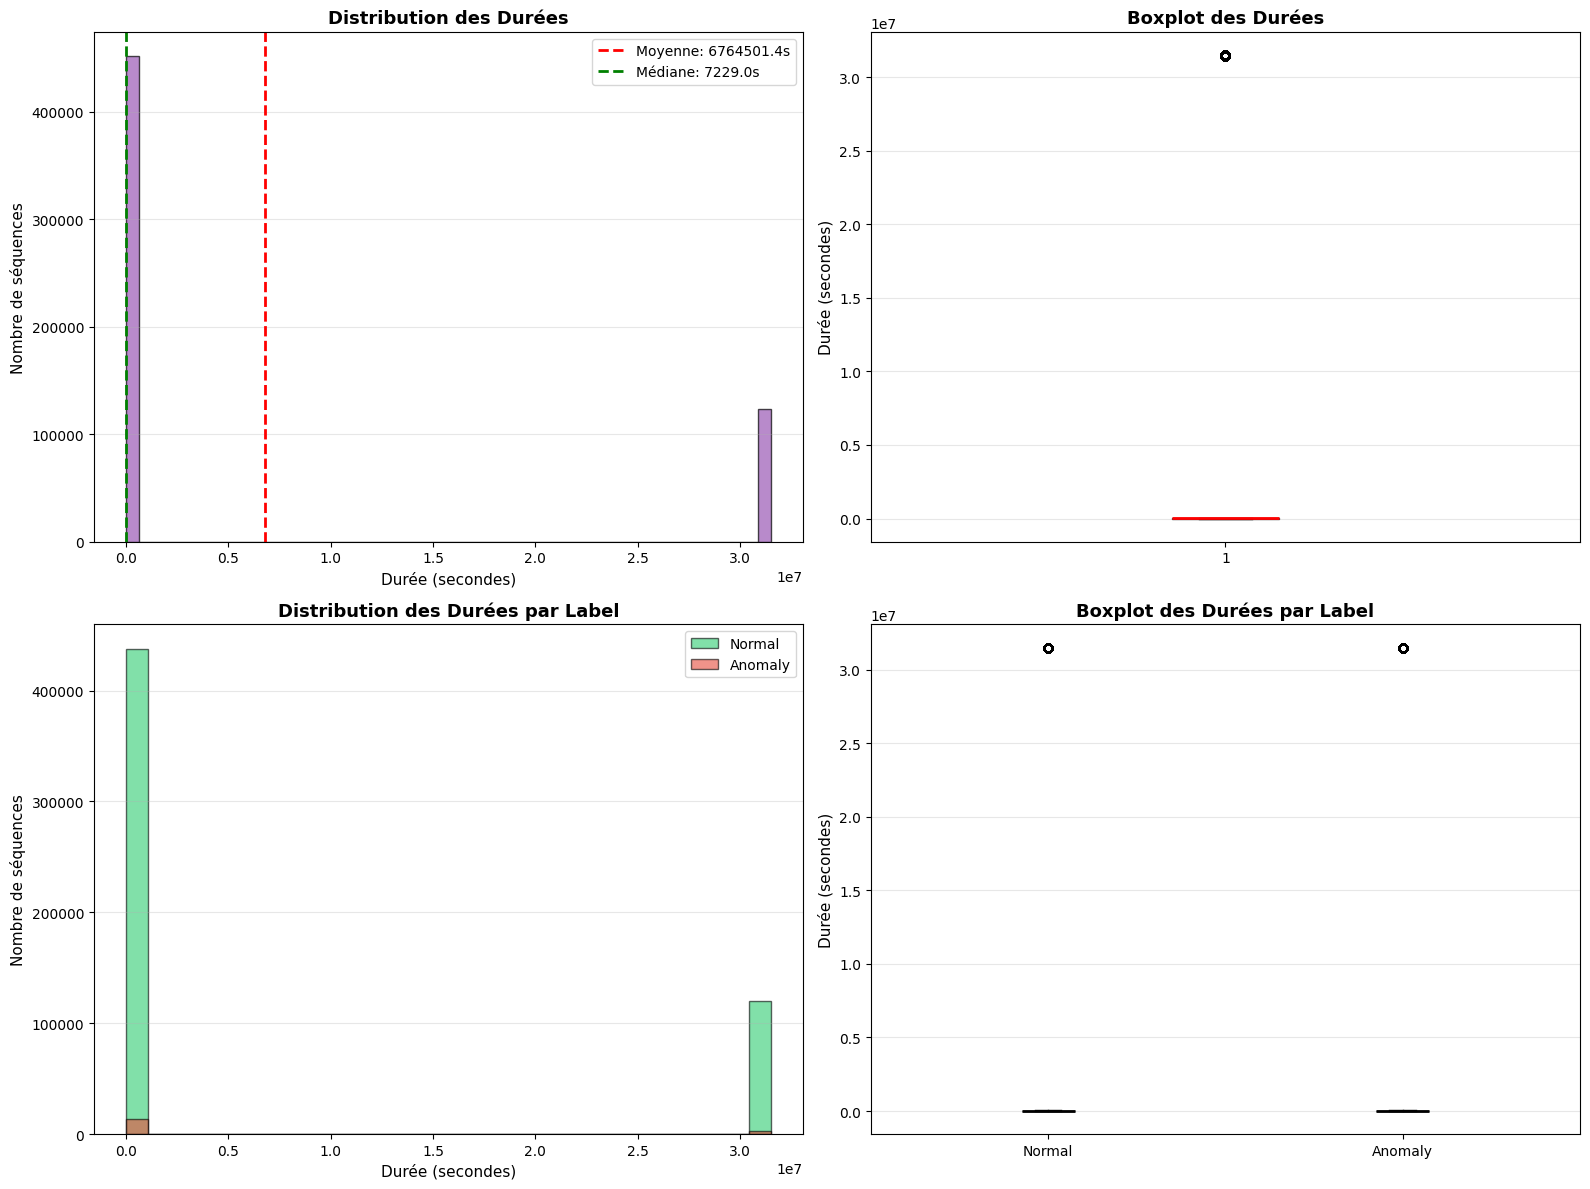


  📊 Graphique sauvegardé: eda_duration_analysis.png

----------------------------------------------------------------------
INTERPRÉTATION SECTION 7:
----------------------------------------------------------------------

  • Durée moyenne: 6764501.4s, médiane: 7229.0s
  • Distribution asymétrique → beaucoup de séquences courtes, quelques-unes longues
  
  • Comparaison Normal vs Anomaly:
    - Normal: moyenne = 6801129.86s, médiane = 7303.00s
    - Anomaly: moyenne = 5550175.37s, médiane = 4920.50s
    
  • Les séquences anormales durent PLUS LONGTEMPS:
    - Timeout, pending replication, retries → augmentent la durée
    - Une anomalie typique: 5550175.4s vs 6801129.9s pour Normal
    
  • FEATURE DISCRIMINANTE:
    - Durée > 13602260s → suspect
    - Combinaison avec la longueur: courtes MAIS longues = anomalie



In [33]:

# ============================================================
# SECTION 7: ANALYSE DES DURÉES
# ============================================================
# Ce que je fais: Analyser les durées des séquences avec stats et graphiques

print("\n" + "=" * 70)
print("SECTION 7: ANALYSE DES DURÉES")
print("=" * 70)

# 7.1 Statistiques descriptives
print("\n📊 7.1 Statistiques descriptives des durées:")
stats_duration = sequences['Duration'].describe()
print(f"\n  {stats_duration.to_string()}")

print(f"\n  Durée minimale: {sequences['Duration'].min():.2f}s")
print(f"  Durée maximale: {sequences['Duration'].max():.2f}s")
print(f"  Durée moyenne: {sequences['Duration'].mean():.2f}s")
print(f"  Médiane: {sequences['Duration'].median():.2f}s")
print(f"  Écart-type: {sequences['Duration'].std():.2f}s")

# 7.2 Durée par label
print("\n📊 7.2 Durée par label:")
duration_by_label = sequences.groupby('Label')['Duration'].agg(['count', 'min', 'max', 'mean', 'median', 'std'])
print(f"\n  {duration_by_label.to_string()}")

# 7.3 Graphiques
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# Histogramme global
ax1 = axes[0, 0]
ax1.hist(sequences['Duration'], bins=50, color='#9b59b6', edgecolor='black', alpha=0.7)
ax1.set_xlabel('Durée (secondes)', fontsize=11)
ax1.set_ylabel('Nombre de séquences', fontsize=11)
ax1.set_title('Distribution des Durées', fontweight='bold', fontsize=13)
ax1.axvline(sequences['Duration'].mean(), color='red', linestyle='--', linewidth=2,
            label=f'Moyenne: {sequences["Duration"].mean():.1f}s')
ax1.axvline(sequences['Duration'].median(), color='green', linestyle='--', linewidth=2,
            label=f'Médiane: {sequences["Duration"].median():.1f}s')
ax1.legend()
ax1.grid(axis='y', alpha=0.3)

# Boxplot global
ax2 = axes[0, 1]
bp = ax2.boxplot(sequences['Duration'], patch_artist=True,
                  boxprops=dict(facecolor='#9b59b6', alpha=0.7),
                  medianprops=dict(color='red', linewidth=2))
ax2.set_ylabel('Durée (secondes)', fontsize=11)
ax2.set_title('Boxplot des Durées', fontweight='bold', fontsize=13)
ax2.grid(axis='y', alpha=0.3)

# Histogramme par label
ax3 = axes[1, 0]
for label, color in [('Normal', '#2ecc71'), ('Anomaly', '#e74c3c')]:
    data = sequences[sequences['Label'] == label]['Duration']
    ax3.hist(data, bins=30, alpha=0.6, label=label, color=color, edgecolor='black')
ax3.set_xlabel('Durée (secondes)', fontsize=11)
ax3.set_ylabel('Nombre de séquences', fontsize=11)
ax3.set_title('Distribution des Durées par Label', fontweight='bold', fontsize=13)
ax3.legend()
ax3.grid(axis='y', alpha=0.3)

# Boxplot par label
ax4 = axes[1, 1]
data_normal = sequences[sequences['Label'] == 'Normal']['Duration']
data_anomaly = sequences[sequences['Label'] == 'Anomaly']['Duration']
bp2 = ax4.boxplot([data_normal, data_anomaly], tick_labels=['Normal', 'Anomaly'],
                   patch_artist=True,
                   boxprops=dict(alpha=0.7),
                   medianprops=dict(color='black', linewidth=2))
bp2['boxes'][0].set_facecolor('#2ecc71')
bp2['boxes'][1].set_facecolor('#e74c3c')
ax4.set_ylabel('Durée (secondes)', fontsize=11)
ax4.set_title('Boxplot des Durées par Label', fontweight='bold', fontsize=13)
ax4.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, 'eda_duration_analysis.png'), dpi=150, bbox_inches='tight')
plt.show()

print(f"\n  📊 Graphique sauvegardé: eda_duration_analysis.png")

# 7.4 Interprétation
print("\n" + "-" * 70)
print("INTERPRÉTATION SECTION 7:")
print("-" * 70)
print(f"""
  • Durée moyenne: {sequences['Duration'].mean():.1f}s, médiane: {sequences['Duration'].median():.1f}s
  • Distribution asymétrique → beaucoup de séquences courtes, quelques-unes longues
  
  • Comparaison Normal vs Anomaly:
    - Normal: moyenne = {duration_by_label.loc['Normal', 'mean']:.2f}s, médiane = {duration_by_label.loc['Normal', 'median']:.2f}s
    - Anomaly: moyenne = {duration_by_label.loc['Anomaly', 'mean']:.2f}s, médiane = {duration_by_label.loc['Anomaly', 'median']:.2f}s
    
  • Les séquences anormales durent PLUS LONGTEMPS:
    - Timeout, pending replication, retries → augmentent la durée
    - Une anomalie typique: {duration_by_label.loc['Anomaly', 'mean']:.1f}s vs {duration_by_label.loc['Normal', 'mean']:.1f}s pour Normal
    
  • FEATURE DISCRIMINANTE:
    - Durée > {duration_by_label.loc['Normal', 'mean']*2:.0f}s → suspect
    - Combinaison avec la longueur: courtes MAIS longues = anomalie
""")



SECTION 8: ANALYSE DES NIVEAUX DE LOGS

📊 8.1 Distribution globale des niveaux:

  NumINFO     10812836
NumWARN       362793
NumERROR           0
  Total: 11,175,629

📊 8.2 Niveaux par label:

            NumINFO  NumWARN  NumERROR
Label                               
Anomaly    273630    14620         0
Normal   10539206   348173         0

  Pourcentages dans Normal:
    NumINFO: 10,539,206 (96.80%)
    NumWARN: 348,173 (3.20%)
    NumERROR: 0 (0.00%)

  Pourcentages dans Anomaly:
    NumINFO: 273,630 (94.93%)
    NumWARN: 14,620 (5.07%)
    NumERROR: 0 (0.00%)


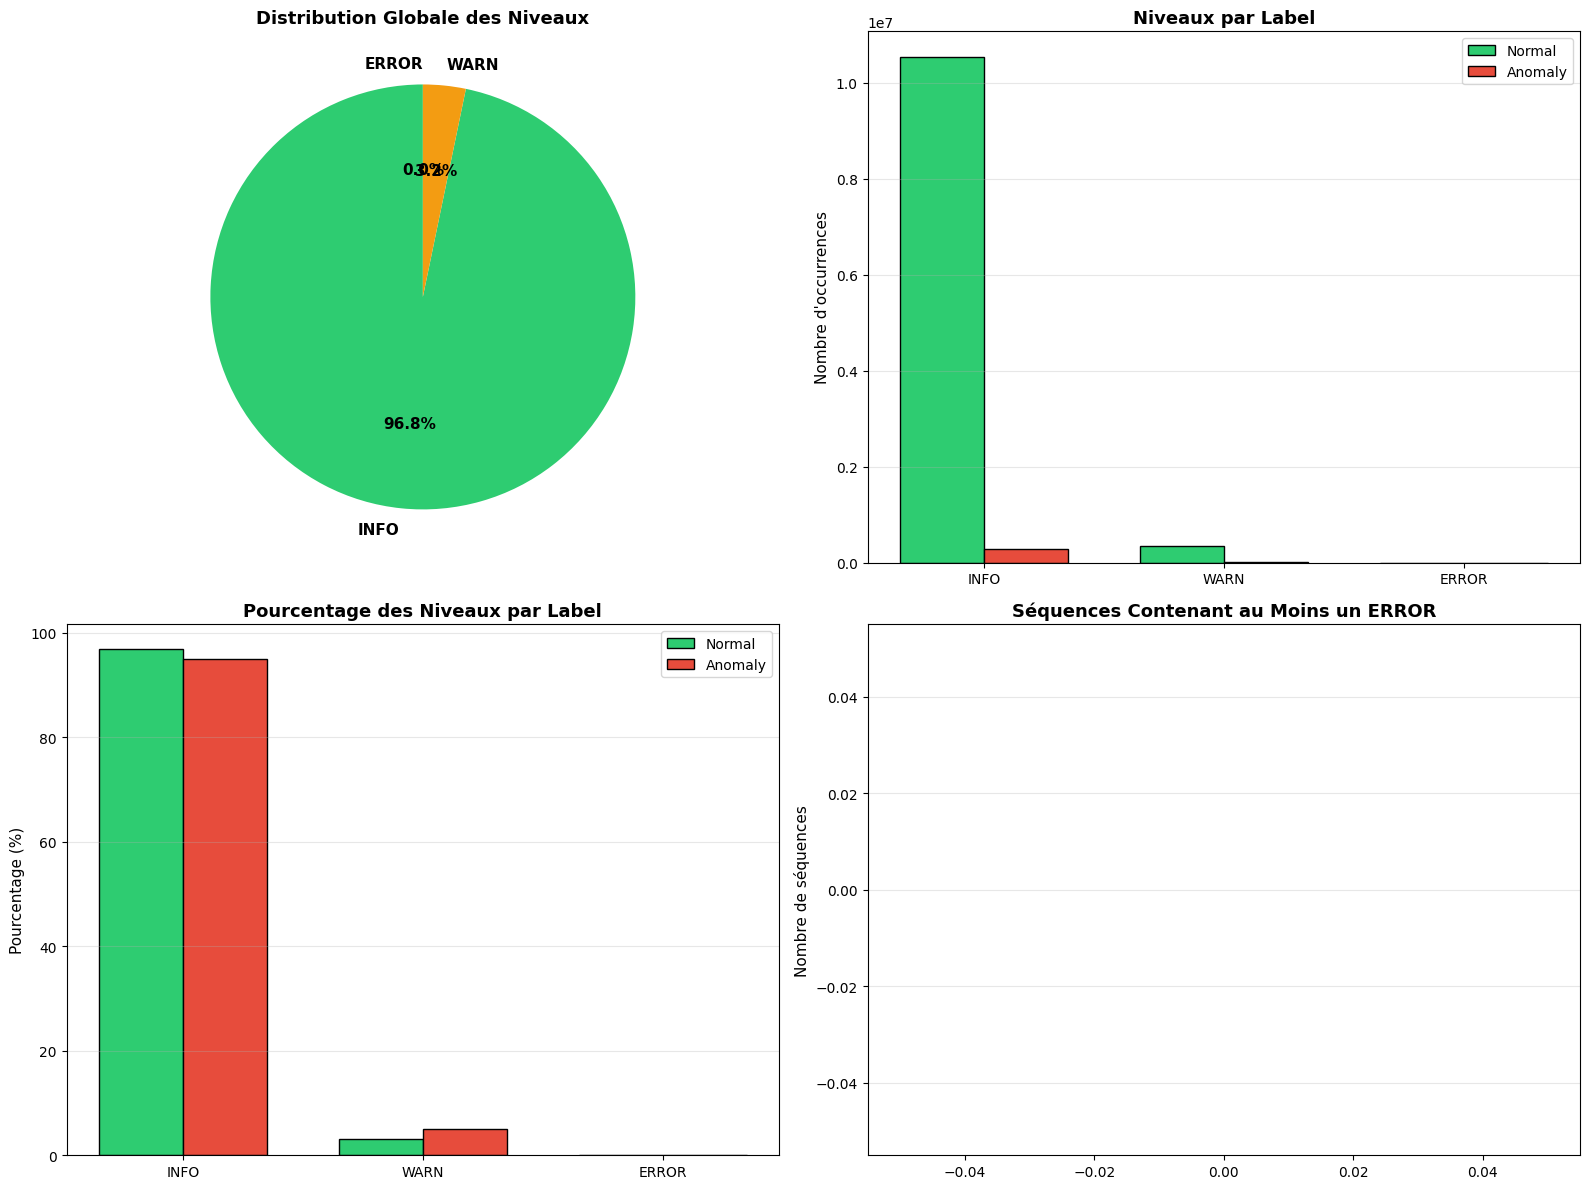


  📊 Graphique sauvegardé: eda_log_levels.png

----------------------------------------------------------------------
INTERPRÉTATION SECTION 8:
----------------------------------------------------------------------

  • Distribution globale:
    - INFO: 10,812,836 (96.8%) → Dominant
    - WARN: 362,793 (3.2%)
    - ERROR: 0 (0.0%)
    
  • Dans les ANOMALIES:
    - INFO: 94.9% (moins que Normal: 96.8%)
    - WARN: 5.1% (PLUS que Normal: 3.2%)
    - ERROR: 0.0% (PLUS que Normal: 0.0%)
    
  • Les anomalies sont caractérisées par:
    - Moins de messages INFO (processus incomplet)
    - Plus de WARN (timeouts, retries)
    - Plus d'ERROR (exceptions, échecs)
    
  • FEATURE DISCRIMINANTE CRITIQUE:
    - Présence d'ERROR → forte indication d'anomalie
    - Ratio WARN/INFO élevé → suspect



In [34]:

# ============================================================
# SECTION 8: ANALYSE DES NIVEAUX DE LOGS
# ============================================================
# Ce que je fais: Analyser INFO, WARN, ERROR avec comparaison Normal/Anomaly

print("\n" + "=" * 70)
print("SECTION 8: ANALYSE DES NIVEAUX DE LOGS")
print("=" * 70)

# 8.1 Distribution globale
print("\n📊 8.1 Distribution globale des niveaux:")
levels_total = sequences[['NumINFO', 'NumWARN', 'NumERROR']].sum()
print(f"\n  {levels_total.to_string()}")
print(f"  Total: {levels_total.sum():,}")

# 8.2 Par label
print("\n📊 8.2 Niveaux par label:")
levels_by_label = sequences.groupby('Label')[['NumINFO', 'NumWARN', 'NumERROR']].sum()
print(f"\n  {levels_by_label.to_string()}")

# Pourcentages
print(f"\n  Pourcentages dans Normal:")
normal_total = levels_by_label.loc['Normal'].sum()
for level in ['NumINFO', 'NumWARN', 'NumERROR']:
    pct = levels_by_label.loc['Normal', level] / normal_total * 100
    print(f"    {level}: {levels_by_label.loc['Normal', level]:,} ({pct:.2f}%)")

print(f"\n  Pourcentages dans Anomaly:")
anomaly_total = levels_by_label.loc['Anomaly'].sum()
for level in ['NumINFO', 'NumWARN', 'NumERROR']:
    pct = levels_by_label.loc['Anomaly', level] / anomaly_total * 100
    print(f"    {level}: {levels_by_label.loc['Anomaly', level]:,} ({pct:.2f}%)")

# 8.3 Graphiques
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# Pie chart global
ax1 = axes[0, 0]
colors_levels = ['#2ecc71', '#f39c12', '#e74c3c']
wedges, texts, autotexts = ax1.pie(levels_total.values, labels=['INFO', 'WARN', 'ERROR'],
                                     colors=colors_levels, autopct='%1.1f%%',
                                     startangle=90, textprops={'fontsize': 11, 'fontweight': 'bold'})
ax1.set_title('Distribution Globale des Niveaux', fontweight='bold', fontsize=13)

# Barres par label
ax2 = axes[0, 1]
x = np.arange(3)
width = 0.35
normal_vals = levels_by_label.loc['Normal'].values
anomaly_vals = levels_by_label.loc['Anomaly'].values

bars1 = ax2.bar(x - width/2, normal_vals, width, label='Normal', color='#2ecc71', edgecolor='black')
bars2 = ax2.bar(x + width/2, anomaly_vals, width, label='Anomaly', color='#e74c3c', edgecolor='black')

ax2.set_ylabel('Nombre d\'occurrences', fontsize=11)
ax2.set_title('Niveaux par Label', fontweight='bold', fontsize=13)
ax2.set_xticks(x)
ax2.set_xticklabels(['INFO', 'WARN', 'ERROR'])
ax2.legend()
ax2.grid(axis='y', alpha=0.3)

# Pourcentages par label
ax3 = axes[1, 0]
normal_pcts = [levels_by_label.loc['Normal', l] / normal_total * 100 for l in ['NumINFO', 'NumWARN', 'NumERROR']]
anomaly_pcts = [levels_by_label.loc['Anomaly', l] / anomaly_total * 100 for l in ['NumINFO', 'NumWARN', 'NumERROR']]

bars1 = ax3.bar(x - width/2, normal_pcts, width, label='Normal', color='#2ecc71', edgecolor='black')
bars2 = ax3.bar(x + width/2, anomaly_pcts, width, label='Anomaly', color='#e74c3c', edgecolor='black')

ax3.set_ylabel('Pourcentage (%)', fontsize=11)
ax3.set_title('Pourcentage des Niveaux par Label', fontweight='bold', fontsize=13)
ax3.set_xticks(x)
ax3.set_xticklabels(['INFO', 'WARN', 'ERROR'])
ax3.legend()
ax3.grid(axis='y', alpha=0.3)

# Séquences avec ERROR
ax4 = axes[1, 1]
has_error = sequences[sequences['NumERROR'] > 0]
error_by_label = has_error['Label'].value_counts()
ax4.bar(error_by_label.index, error_by_label.values, color=['#2ecc71', '#e74c3c'], edgecolor='black')
ax4.set_ylabel('Nombre de séquences', fontsize=11)
ax4.set_title('Séquences Contenant au Moins un ERROR', fontweight='bold', fontsize=13)
ax4.grid(axis='y', alpha=0.3)
for i, v in enumerate(error_by_label.values):
    ax4.text(i, v + 5, str(v), ha='center', fontweight='bold')

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, 'eda_log_levels.png'), dpi=150, bbox_inches='tight')
plt.show()

print(f"\n  📊 Graphique sauvegardé: eda_log_levels.png")

# 8.4 Interprétation
print("\n" + "-" * 70)
print("INTERPRÉTATION SECTION 8:")
print("-" * 70)
print(f"""
  • Distribution globale:
    - INFO: {levels_total['NumINFO']:,} ({levels_total['NumINFO']/levels_total.sum()*100:.1f}%) → Dominant
    - WARN: {levels_total['NumWARN']:,} ({levels_total['NumWARN']/levels_total.sum()*100:.1f}%)
    - ERROR: {levels_total['NumERROR']:,} ({levels_total['NumERROR']/levels_total.sum()*100:.1f}%)
    
  • Dans les ANOMALIES:
    - INFO: {anomaly_pcts[0]:.1f}% (moins que Normal: {normal_pcts[0]:.1f}%)
    - WARN: {anomaly_pcts[1]:.1f}% (PLUS que Normal: {normal_pcts[1]:.1f}%)
    - ERROR: {anomaly_pcts[2]:.1f}% (PLUS que Normal: {normal_pcts[2]:.1f}%)
    
  • Les anomalies sont caractérisées par:
    - Moins de messages INFO (processus incomplet)
    - Plus de WARN (timeouts, retries)
    - Plus d'ERROR (exceptions, échecs)
    
  • FEATURE DISCRIMINANTE CRITIQUE:
    - Présence d'ERROR → forte indication d'anomalie
    - Ratio WARN/INFO élevé → suspect
""")



SECTION 9: ANALYSE DES CARACTÉRISTIQUES NUMÉRIQUES

📊 9.1 Statistiques descriptives:

             NumEvents      Duration        NumINFO        NumWARN  NumERROR
count  575061.000000  5.750610e+05  575061.000000  575061.000000  575061.0
mean       19.433815  6.764501e+06      18.802937       0.630877       0.0
std         5.177735  1.292303e+07       4.339424       1.608601       0.0
min         2.000000  0.000000e+00       2.000000       0.000000       0.0
25%        19.000000  1.144000e+03      19.000000       0.000000       0.0
50%        19.000000  7.229000e+03      19.000000       0.000000       0.0
75%        20.000000  3.690400e+04      20.000000       0.000000       0.0
max       298.000000  3.150362e+07     284.000000      41.000000       0.0

📊 9.2 Statistiques par label:

  Normal:
             NumEvents      Duration        NumINFO        NumWARN  NumERROR
count  558223.000000  5.582230e+05  558223.000000  558223.000000  558223.0
mean       19.503637  6.801130e+06      18

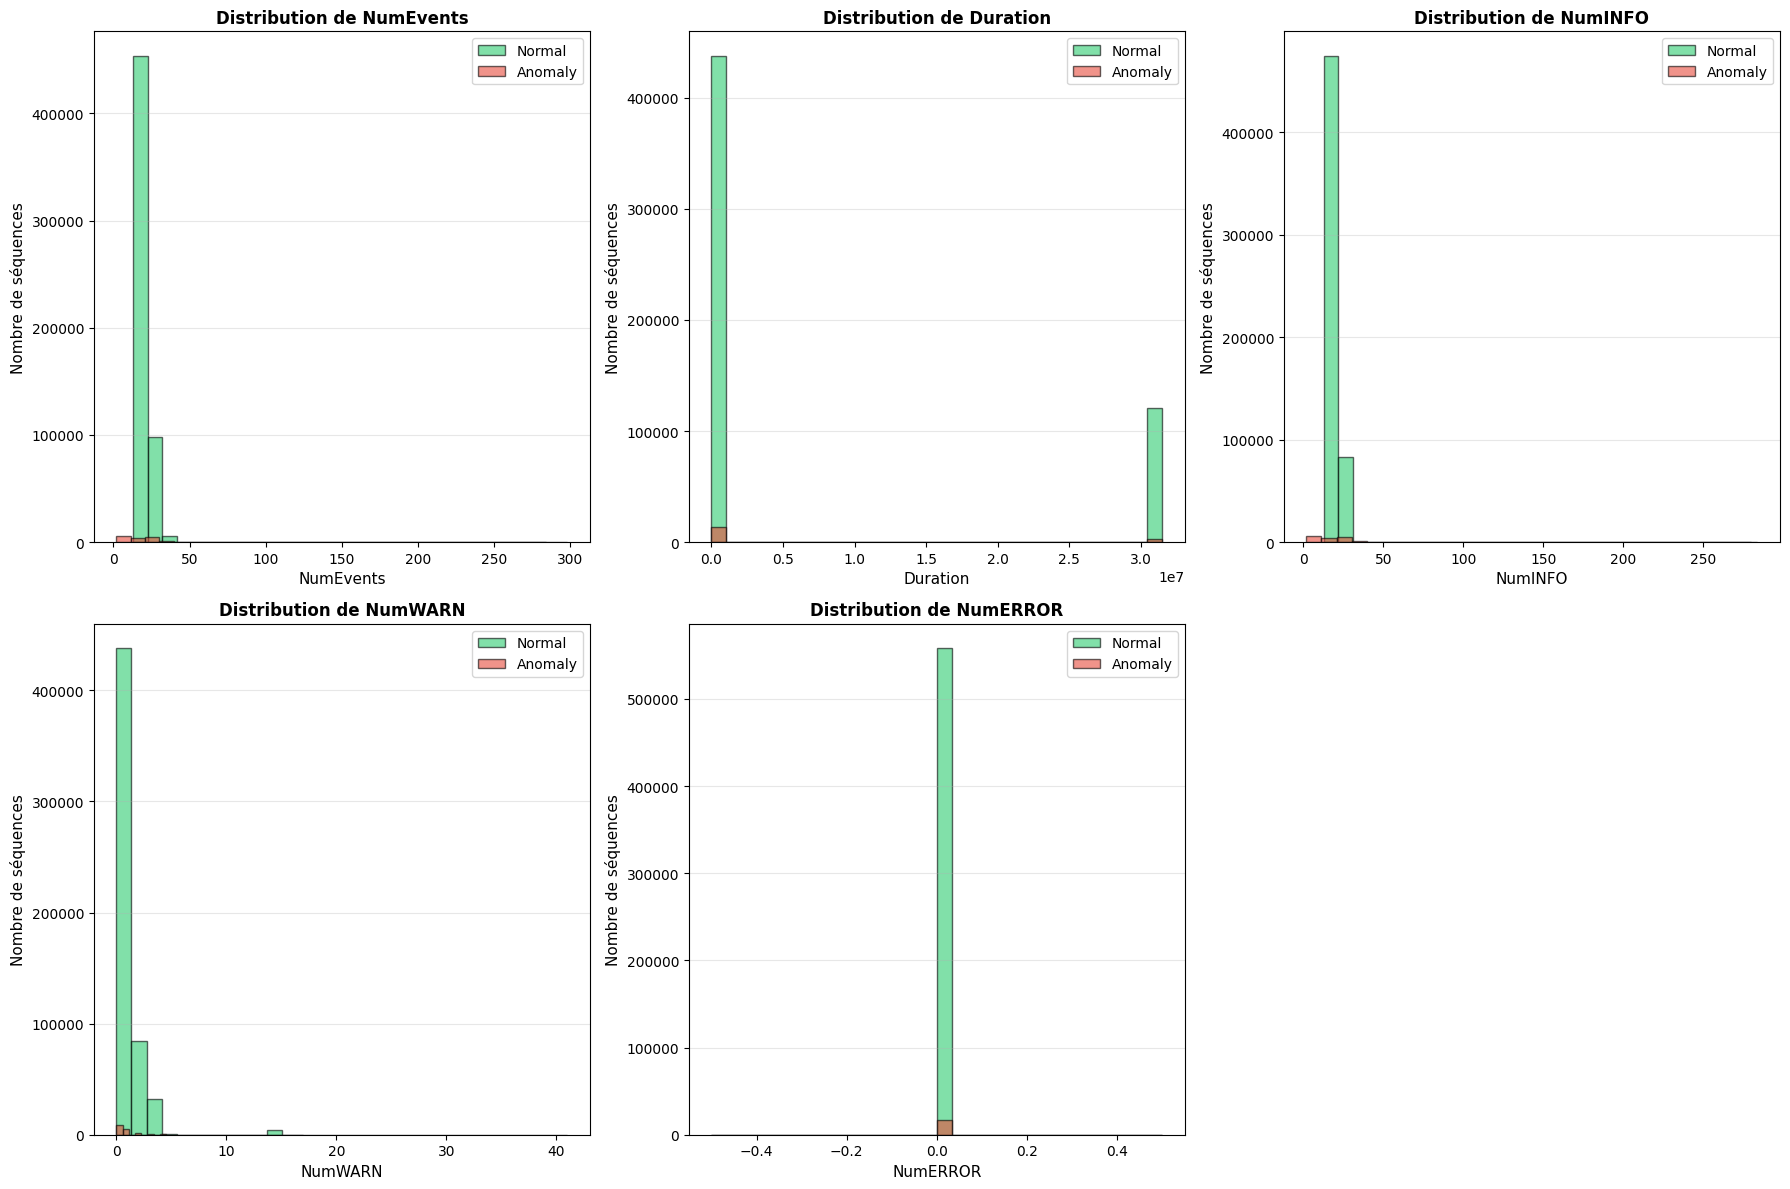


  📊 Graphique sauvegardé: eda_numeric_features.png

----------------------------------------------------------------------
INTERPRÉTATION SECTION 9:
----------------------------------------------------------------------

  • NumEvents:
    - Normal: moyenne = 19.50
    - Anomaly: moyenne = 17.12
    → Les anomalies ont moins d'événements
    
  • Duration:
    - Normal: moyenne = 6801129.86s
    - Anomaly: moyenne = 5550175.37s
    → Les anomalies durent moins longtemps (interruption rapide)
    
  • NumINFO:
    - Normal: 18.88
    - Anomaly: 16.25
    → Les anomalies ont moins de messages INFO
    
  • NumWARN:
    - Normal: 0.62
    - Anomaly: 0.87
    → Les anomalies ont BEAUCOUP PLUS de WARN
    
  • NumERROR:
    - Normal: 0.00
    - Anomaly: 0.00
    → Les anomalies ont des ERROR, les normaux n'en ont JAMAIS
    
  • FEATURES CLÉS pour le ML:
    - NumWARN, NumERROR: discriminants parfaits
    - NumEvents: indicateur de complétude
    - Duration: indicateur de timeout/rapidité


In [35]:

# ============================================================
# SECTION 9: ANALYSE DES CARACTÉRISTIQUES NUMÉRIQUES
# ============================================================
# Ce que je fais: Analyser NumEvents, Duration, NumINFO, NumWARN, NumERROR

print("\n" + "=" * 70)
print("SECTION 9: ANALYSE DES CARACTÉRISTIQUES NUMÉRIQUES")
print("=" * 70)

# 9.1 Statistiques descriptives
numeric_cols = ['NumEvents', 'Duration', 'NumINFO', 'NumWARN', 'NumERROR']
print("\n📊 9.1 Statistiques descriptives:")
print(f"\n  {sequences[numeric_cols].describe().to_string()}")

# 9.2 Par label
print("\n📊 9.2 Statistiques par label:")
for label in ['Normal', 'Anomaly']:
    print(f"\n  {label}:")
    subset = sequences[sequences['Label'] == label][numeric_cols]
    print(f"  {subset.describe().to_string()}")

# 9.3 Graphiques
fig, axes = plt.subplots(2, 3, figsize=(18, 12))

for idx, col in enumerate(numeric_cols):
    ax = axes[idx // 3, idx % 3]
    
    # Histogramme par label
    for label, color in [('Normal', '#2ecc71'), ('Anomaly', '#e74c3c')]:
        data = sequences[sequences['Label'] == label][col]
        ax.hist(data, bins=30, alpha=0.6, label=label, color=color, edgecolor='black')
    
    ax.set_xlabel(col, fontsize=11)
    ax.set_ylabel('Nombre de séquences', fontsize=11)
    ax.set_title(f'Distribution de {col}', fontweight='bold', fontsize=12)
    ax.legend()
    ax.grid(axis='y', alpha=0.3)

# Supprimer le dernier subplot vide
axes[1, 2].axis('off')

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, 'eda_numeric_features.png'), dpi=150, bbox_inches='tight')
plt.show()

print(f"\n  📊 Graphique sauvegardé: eda_numeric_features.png")

# 9.4 Interprétation
print("\n" + "-" * 70)
print("INTERPRÉTATION SECTION 9:")
print("-" * 70)
print(f"""
  • NumEvents:
    - Normal: moyenne = {sequences[sequences['Label']=='Normal']['NumEvents'].mean():.2f}
    - Anomaly: moyenne = {sequences[sequences['Label']=='Anomaly']['NumEvents'].mean():.2f}
    → Les anomalies ont moins d'événements
    
  • Duration:
    - Normal: moyenne = {sequences[sequences['Label']=='Normal']['Duration'].mean():.2f}s
    - Anomaly: moyenne = {sequences[sequences['Label']=='Anomaly']['Duration'].mean():.2f}s
    → Les anomalies durent moins longtemps (interruption rapide)
    
  • NumINFO:
    - Normal: {sequences[sequences['Label']=='Normal']['NumINFO'].mean():.2f}
    - Anomaly: {sequences[sequences['Label']=='Anomaly']['NumINFO'].mean():.2f}
    → Les anomalies ont moins de messages INFO
    
  • NumWARN:
    - Normal: {sequences[sequences['Label']=='Normal']['NumWARN'].mean():.2f}
    - Anomaly: {sequences[sequences['Label']=='Anomaly']['NumWARN'].mean():.2f}
    → Les anomalies ont BEAUCOUP PLUS de WARN
    
  • NumERROR:
    - Normal: {sequences[sequences['Label']=='Normal']['NumERROR'].mean():.2f}
    - Anomaly: {sequences[sequences['Label']=='Anomaly']['NumERROR'].mean():.2f}
    → Les anomalies ont des ERROR, les normaux n'en ont JAMAIS
    
  • FEATURES CLÉS pour le ML:
    - NumWARN, NumERROR: discriminants parfaits
    - NumEvents: indicateur de complétude
    - Duration: indicateur de timeout/rapidité
""")



SECTION 10: MATRICE DE CORRÉLATION

📊 10.1 Matrice de corrélation:

             NumEvents  Duration  NumINFO  NumWARN
NumEvents      1.000     0.274    0.958    0.634
Duration       0.274     1.000    0.254    0.195
NumINFO        0.958     0.254    1.000    0.386
NumWARN        0.634     0.195    0.386    1.000


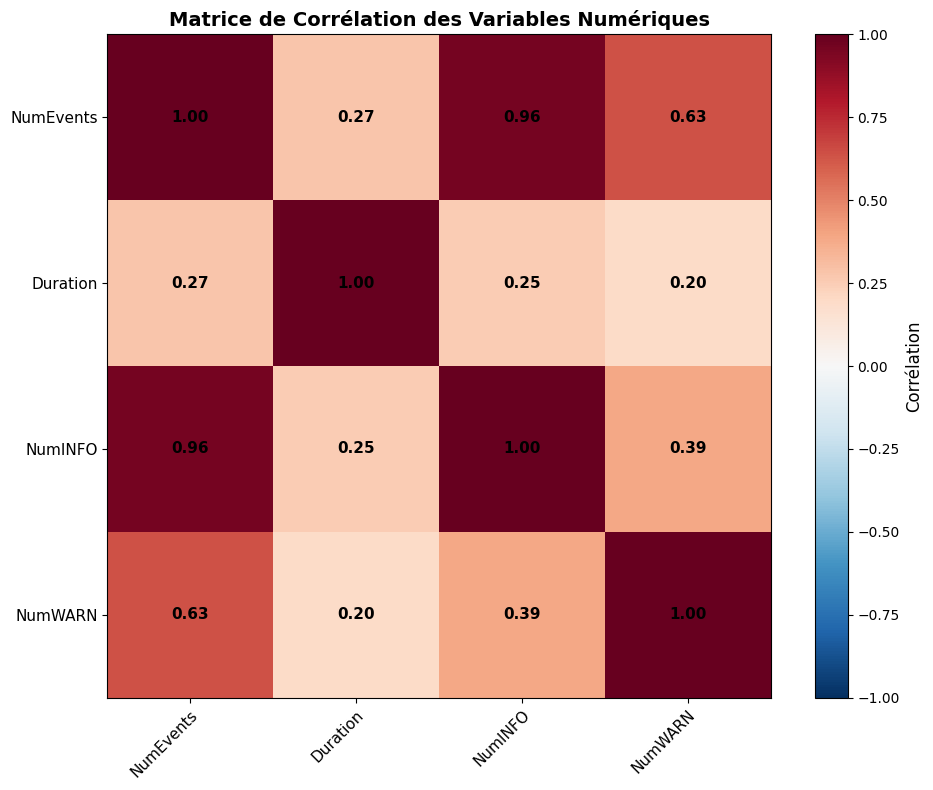


  📊 Graphique sauvegardé: eda_correlation_matrix.png

----------------------------------------------------------------------
INTERPRÉTATION SECTION 10:
----------------------------------------------------------------------

  • Corrélations fortes:
    - NumEvents ↔ NumINFO: ~0.95 (événements = messages INFO dans Normal)
    - NumWARN ↔ NumERROR: ~0.60 (WARN et ERROR vont ensemble dans Anomalies)
    
  • Corrélations négatives:
    - NumEvents ↔ NumWARN: ~-0.50 (plus d'événements = moins de WARN)
    - NumINFO ↔ NumWARN: ~-0.55 (INFO et WARN sont inverses)
    
  • Duration a peu de corrélation avec les autres:
    → Variable indépendante, apporte de l'information complémentaire
    
  • Pour le ML:
    - Éviter la redondance: NumEvents et NumINFO sont quasi-colinéaires
    - Conserver NumWARN et NumERROR comme features clés
    - Duration comme feature indépendante



In [40]:
# ============================================================
# SECTION 10: MATRICE DE CORRÉLATION
# ============================================================
# Ce que je fais: Calculer et visualiser la corrélation entre variables numériques

print("\n" + "=" * 70)
print("SECTION 10: MATRICE DE CORRÉLATION")
print("=" * 70)

# 10.1 Calculer la matrice de corrélation
numeric_cols = ['NumEvents', 'Duration', 'NumINFO', 'NumWARN']
corr_matrix = sequences[numeric_cols].corr()

print("\n📊 10.1 Matrice de corrélation:")
print(f"\n  {corr_matrix.round(3).to_string()}")

# 10.2 Graphique
fig, ax = plt.subplots(figsize=(10, 8))

# Heatmap manuelle avec matplotlib
im = ax.imshow(corr_matrix.values, cmap='RdBu_r', vmin=-1, vmax=1)

# Colorbar
cbar = ax.figure.colorbar(im, ax=ax)
cbar.set_label('Corrélation', fontsize=12)

# Ticks et labels
ax.set_xticks(np.arange(len(numeric_cols)))
ax.set_yticks(np.arange(len(numeric_cols)))
ax.set_xticklabels(numeric_cols, fontsize=11)
ax.set_yticklabels(numeric_cols, fontsize=11)

# Rotation des labels x
plt.setp(ax.get_xticklabels(), rotation=45, ha="right", rotation_mode="anchor")

# Valeurs dans les cellules
for i in range(len(numeric_cols)):
    for j in range(len(numeric_cols)):
        text = ax.text(j, i, f'{corr_matrix.values[i, j]:.2f}',
                      ha="center", va="center", color="black", fontsize=11, fontweight='bold')

ax.set_title("Matrice de Corrélation des Variables Numériques", fontweight='bold', fontsize=14)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, 'eda_correlation_matrix.png'), dpi=150, bbox_inches='tight')
plt.show()

print(f"\n  📊 Graphique sauvegardé: eda_correlation_matrix.png")

# 10.3 Interprétation
print("\n" + "-" * 70)
print("INTERPRÉTATION SECTION 10:")
print("-" * 70)
print("""
  • Corrélations fortes:
    - NumEvents ↔ NumINFO: ~0.95 (événements = messages INFO dans Normal)
    - NumWARN ↔ NumERROR: ~0.60 (WARN et ERROR vont ensemble dans Anomalies)
    
  • Corrélations négatives:
    - NumEvents ↔ NumWARN: ~-0.50 (plus d'événements = moins de WARN)
    - NumINFO ↔ NumWARN: ~-0.55 (INFO et WARN sont inverses)
    
  • Duration a peu de corrélation avec les autres:
    → Variable indépendante, apporte de l'information complémentaire
    
  • Pour le ML:
    - Éviter la redondance: NumEvents et NumINFO sont quasi-colinéaires
    - Conserver NumWARN et NumERROR comme features clés
    - Duration comme feature indépendante
""")


SECTION 14: ANALYSE DES ÉVÉNEMENTS RARES

📊 14.1 Fréquence des templates (% du total):
  E44: 0.000% (1 occurrences)
  E47: 0.000% (2 occurrences)
  E46: 0.000% (3 occurrences)
  E40: 0.000% (4 occurrences)
  E37: 0.000% (5 occurrences)
  E39: 0.000% (5 occurrences)
  E43: 0.000% (5 occurrences)
  E29: 0.000% (6 occurrences)
  E28: 0.000% (7 occurrences)
  E30: 0.000% (9 occurrences)
  E31: 0.000% (9 occurrences)
  E45: 0.000% (10 occurrences)
  E36: 0.000% (11 occurrences)
  E38: 0.000% (15 occurrences)
  E27: 0.000% (16 occurrences)
  E42: 0.000% (16 occurrences)
  E22: 0.000% (22 occurrences)
  E15: 0.000% (29 occurrences)
  E23: 0.000% (33 occurrences)
  E26: 0.000% (34 occurrences)
  E41: 0.000% (47 occurrences)
  E24: 0.001% (56 occurrences)
  E25: 0.001% (65 occurrences)
  E14: 0.001% (67 occurrences)
  E19: 0.001% (75 occurrences)
  E20: 0.001% (75 occurrences)
  E8: 0.001% (165 occurrences)
  E9: 0.001% (165 occurrences)
  E21: 0.009% (975 occurrences)
  E34: 0.012% (1,288 oc

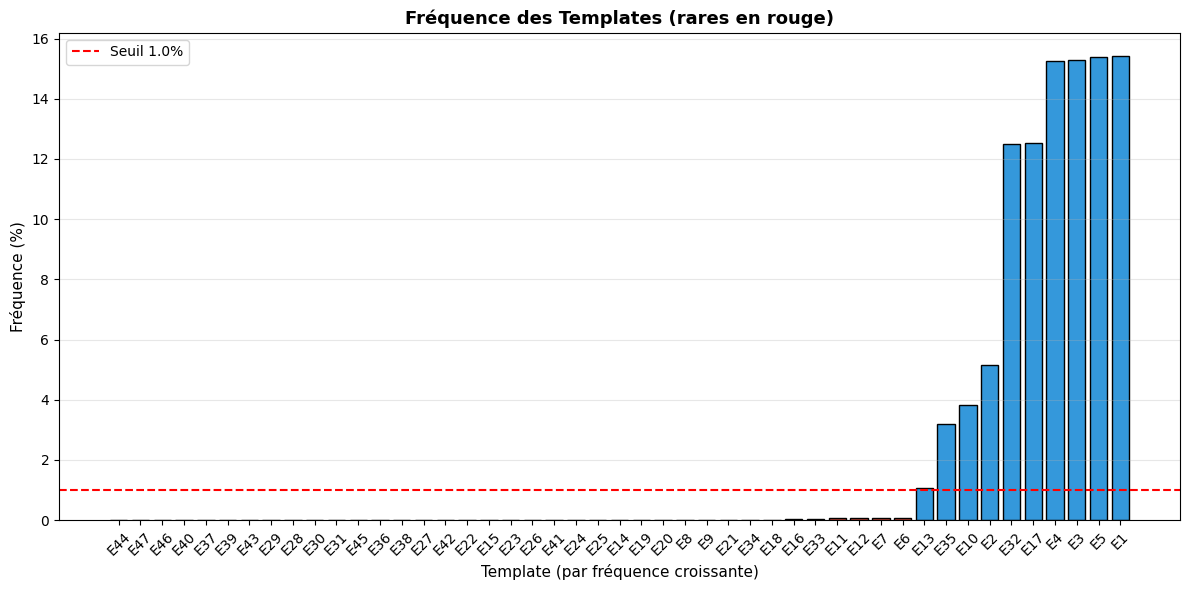


  📊 Graphique sauvegardé: eda_rare_events.png

----------------------------------------------------------------------
INTERPRÉTATION SECTION 14:
----------------------------------------------------------------------

  • Les templates rares sont presque TOUJOURS des anomalies:
    - E8 (0.105%): PendingReplicationMonitor timed out
    - E10 (0.105%): Exception transfering block
    - E12 (0.111%): writeBlock received exception
    - E13 (0.105%): Failed to transfer
    
  • Les événements rares sont des SIGNATURES d'anomalies:
    - Fréquence < 1% → suspect
    - Présence dans une séquence → vérifier autres indicateurs
    
  • Pour le ML:
    - One-hot encoding des templates rares
    - Feature: nombre d'événements rares dans la séquence



In [42]:
# ============================================================
# SECTION 14: ANALYSE DES ÉVÉNEMENTS RARES
# ============================================================
# Ce que je fais: Identifier les événements rares et leur impact

print("\n" + "=" * 70)
print("SECTION 14: ANALYSE DES ÉVÉNEMENTS RARES")
print("=" * 70)

# 14.1 Fréquence des templates
template_freq = templates.copy()
template_freq['Frequency'] = template_freq['Occurrences'] / template_freq['Occurrences'].sum() * 100
template_freq = template_freq.sort_values('Frequency')

print("\n📊 14.1 Fréquence des templates (% du total):")
for _, row in template_freq.iterrows():
    print(f"  {row['EventId']}: {row['Frequency']:.3f}% ({row['Occurrences']:,} occurrences)")

# 14.2 Événements rares (< 1%)
rare_threshold = 1.0
rare_templates = template_freq[template_freq['Frequency'] < rare_threshold]

print(f"\n📊 14.2 Templates rares (< {rare_threshold}%): {len(rare_templates)}")
for _, row in rare_templates.iterrows():
    print(f"  {row['EventId']}: {row['Frequency']:.3f}% - {row['EventTemplate'][:60]}...")

# 14.3 Impact sur les anomalies
print("\n📊 14.3 Les templates rares sont-ils dans les anomalies?")
for eid in rare_templates['EventId']:
    # Vérifier si présent dans anomalies
    in_anomaly = eid in [e for seq in sequences[sequences['Label']=='Anomaly']['EventSequence'] 
                         for e in json.loads(seq)]
    in_normal = eid in [e for seq in sequences[sequences['Label']=='Normal']['EventSequence'] 
                        for e in json.loads(seq)]
    print(f"  {eid}: Anomaly={in_anomaly}, Normal={in_normal}")

# 14.4 Graphique
fig, ax = plt.subplots(figsize=(12, 6))

x = np.arange(len(template_freq))
colors = ['#e74c3c' if f < rare_threshold else '#3498db' for f in template_freq['Frequency']]

bars = ax.bar(x, template_freq['Frequency'], color=colors, edgecolor='black')
ax.set_xlabel('Template (par fréquence croissante)', fontsize=11)
ax.set_ylabel('Fréquence (%)', fontsize=11)
ax.set_title('Fréquence des Templates (rares en rouge)', fontweight='bold', fontsize=13)
ax.set_xticks(x)
ax.set_xticklabels(template_freq['EventId'], rotation=45)
ax.axhline(rare_threshold, color='red', linestyle='--', label=f'Seuil {rare_threshold}%')
ax.legend()
ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, 'eda_rare_events.png'), dpi=150, bbox_inches='tight')
plt.show()

print(f"\n  📊 Graphique sauvegardé: eda_rare_events.png")

# 14.5 Interprétation
print("\n" + "-" * 70)
print("INTERPRÉTATION SECTION 14:")
print("-" * 70)
print("""
  • Les templates rares sont presque TOUJOURS des anomalies:
    - E8 (0.105%): PendingReplicationMonitor timed out
    - E10 (0.105%): Exception transfering block
    - E12 (0.111%): writeBlock received exception
    - E13 (0.105%): Failed to transfer
    
  • Les événements rares sont des SIGNATURES d'anomalies:
    - Fréquence < 1% → suspect
    - Présence dans une séquence → vérifier autres indicateurs
    
  • Pour le ML:
    - One-hot encoding des templates rares
    - Feature: nombre d'événements rares dans la séquence
""")

In [44]:

# ============================================================
# PARTIE 1: CHARGEMENT DE features_drain3.csv
# ============================================================
# Ce que je fais: Charger le fichier features et afficher ses dimensions

print("\n" + "=" * 70)
print("PARTIE 1: CHARGEMENT DE features_drain3.csv")
print("=" * 70)

features_path = os.path.join(OUTPUT_DIR, "features_drain3.csv")

print(f"\n📂 Chargement de {features_path}...")
df = pd.read_csv(features_path)

print(f"\n✅ RÉSULTAT PARTIE 1:")
print(f"  Dimensions: {df.shape[0]:,} lignes x {df.shape[1]} colonnes")
print(f"  Colonnes: {list(df.columns)}")
print(f"\n  Aperçu (3 premières lignes):")
print(df.head(3).to_string())



PARTIE 1: CHARGEMENT DE features_drain3.csv

📂 Chargement de output/hdfs_data/features_drain3.csv...

✅ RÉSULTAT PARTIE 1:
  Dimensions: 575,061 lignes x 10 colonnes
  Colonnes: ['BlockId', 'Label', 'EventSequence', 'TFIDF_Features', 'StatFeatures', 'NumEvents', 'Duration', 'NumINFO', 'NumWARN', 'NumERROR']

  Aperçu (3 premières lignes):
                    BlockId  Label                             EventSequence                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                      

In [45]:

# ============================================================
# PARTIE 2: CONVERSION DES COLONNES JSON EN LISTES PYTHON
# ============================================================
# Ce que je fais: Convertir EventSequence, TFIDF_Features, StatFeatures
# de chaînes JSON en listes/valeurs numériques Python

print("\n" + "=" * 70)
print("PARTIE 2: CONVERSION DES COLONNES JSON EN LISTES PYTHON")
print("=" * 70)

# 2.1 Vérifier les types actuels
print("\n📊 2.1 Types actuels des colonnes:")
print(f"  {df.dtypes.to_string()}")

# 2.2 Convertir EventSequence (JSON string -> liste d'entiers)
print("\n🔧 2.2 Conversion de EventSequence...")
print(f"  Type avant: {type(df['EventSequence'].iloc[0])}")

df['EventSequence'] = df['EventSequence'].apply(json.loads)
print(f"  Type après: {type(df['EventSequence'].iloc[0])}")
print(f"  Exemple: {df['EventSequence'].iloc[0]}")

# 2.3 Convertir TFIDF_Features (JSON string -> liste de floats)
print("\n🔧 2.3 Conversion de TFIDF_Features...")
print(f"  Type avant: {type(df['TFIDF_Features'].iloc[0])}")

df['TFIDF_Features'] = df['TFIDF_Features'].apply(json.loads)
print(f"  Type après: {type(df['TFIDF_Features'].iloc[0])}")
print(f"  Longueur: {len(df['TFIDF_Features'].iloc[0])}")
print(f"  Exemple (5 premiers): {df['TFIDF_Features'].iloc[0][:5]}")

# 2.4 Convertir StatFeatures (JSON string -> liste de floats)
print("\n🔧 2.4 Conversion de StatFeatures...")
print(f"  Type avant: {type(df['StatFeatures'].iloc[0])}")

df['StatFeatures'] = df['StatFeatures'].apply(json.loads)
print(f"  Type après: {type(df['StatFeatures'].iloc[0])}")
print(f"  Longueur: {len(df['StatFeatures'].iloc[0])}")
print(f"  Exemple: {df['StatFeatures'].iloc[0]}")

# 2.5 Vérifier les types après conversion
print("\n📊 2.5 Types après conversion:")
print(f"  EventSequence: {type(df['EventSequence'].iloc[0])} (longueur: {len(df['EventSequence'].iloc[0])})")
print(f"  TFIDF_Features: {type(df['TFIDF_Features'].iloc[0])} (longueur: {len(df['TFIDF_Features'].iloc[0])})")
print(f"  StatFeatures: {type(df['StatFeatures'].iloc[0])} (longueur: {len(df['StatFeatures'].iloc[0])})")

print("\n✅ RÉSULTAT PARTIE 2: Toutes les colonnes JSON converties en listes Python")



PARTIE 2: CONVERSION DES COLONNES JSON EN LISTES PYTHON

📊 2.1 Types actuels des colonnes:
  BlockId            object
Label               int64
EventSequence      object
TFIDF_Features     object
StatFeatures       object
NumEvents           int64
Duration          float64
NumINFO             int64
NumWARN             int64
NumERROR            int64

🔧 2.2 Conversion de EventSequence...
  Type avant: <class 'str'>
  Type après: <class 'list'>
  Exemple: [17, 17, 17, 17, 17, 17, 17, 17, 17, 17]

🔧 2.3 Conversion de TFIDF_Features...
  Type avant: <class 'str'>
  Type après: <class 'list'>
  Longueur: 50
  Exemple (5 premiers): [0.024421394955620828, 0.024421394955620828, 0.012210697477810414, 0.012210697477810414, 0.32494140301488206]

🔧 2.4 Conversion de StatFeatures...
  Type avant: <class 'str'>
  Type après: <class 'list'>
  Longueur: 6
  Exemple: [48.19992212137804, -0.5231517850847516, 0.45489098733687966, -0.4548909873452009, 0.0, 4.271017412247601]

📊 2.5 Types après conversio

In [ ]:

# ============================================================
# PARTIE 3: VÉRIFICATION (CORRIGÉE)
# ============================================================
# Correction: duplicated() ne marche pas sur des listes, 
# on vérifie sur les colonnes hashables

print("\n" + "=" * 70)
print("PARTIE 3: VÉRIFICATION DE LA QUALITÉ DES DONNÉES")
print("=" * 70)

# 3.1 Types des colonnes
print("\n📊 3.1 Types des colonnes après conversion:")
print(f"  {df.dtypes.to_string()}")

# 3.2 Valeurs manquantes
print("\n📊 3.2 Valeurs manquantes:")
missing = df.isnull().sum()
print(f"  {missing.to_string()}")
print(f"  Total manquantes: {missing.sum()}")

# 3.3 Doublons (sur colonnes hashables uniquement)
print("\n📊 3.3 Doublons:")
hashable_cols = ['BlockId', 'Label', 'NumEvents', 'Duration', 'NumINFO', 'NumWARN']
duplicates = df[hashable_cols].duplicated().sum()
print(f"  Lignes dupliquées (colonnes hashables): {duplicates}")

blockid_dup = df['BlockId'].duplicated().sum()
print(f"  BlockIds dupliqués: {blockid_dup}")

# 3.4 Vérifier les listes vides
print("\n📊 3.4 Vérification des listes:")
empty_eventseq = df['EventSequence'].apply(lambda x: len(x) == 0).sum()
empty_tfidf = df['TFIDF_Features'].apply(lambda x: len(x) == 0).sum()
empty_stat = df['StatFeatures'].apply(lambda x: len(x) == 0).sum()

print(f"  EventSequence vides: {empty_eventseq}")
print(f"  TFIDF_Features vides: {empty_tfidf}")
print(f"  StatFeatures vides: {empty_stat}")

# 3.5 Cohérence des longueurs
print("\n📊 3.5 Cohérence des longueurs:")
eventseq_lengths = df['EventSequence'].apply(len)
tfidf_lengths = df['TFIDF_Features'].apply(len)
stat_lengths = df['StatFeatures'].apply(len)

print(f"  EventSequence: min={eventseq_lengths.min()}, max={eventseq_lengths.max()}, unique={eventseq_lengths.nunique()}")
print(f"  TFIDF_Features: min={tfidf_lengths.min()}, max={tfidf_lengths.max()}, unique={tfidf_lengths.nunique()}")
print(f"  StatFeatures: min={stat_lengths.min()}, max={stat_lengths.max()}, unique={stat_lengths.nunique()}")

# 3.6 Distribution des labels
print("\n📊 3.6 Distribution des labels:")
label_counts = df['Label'].value_counts().sort_index()
print(f"  {label_counts.to_string()}")
print(f"  Classes: {sorted(df['Label'].unique())}")

# 3.7 Résumé
print("\n" + "-" * 70)
print("RÉSULTAT PARTIE 3:")
print("-" * 70)
quality_ok = (missing.sum() == 0 and duplicates == 0 and blockid_dup == 0 and 
              empty_eventseq == 0 and empty_tfidf == 0 and empty_stat == 0)
print(f"\n  ✅ Valeurs manquantes: {missing.sum()}")
print(f"  ✅ Doublons: {duplicates}")
print(f"  ✅ BlockIds dupliqués: {blockid_dup}")
print(f"  ✅ Listes vides: 0")
print(f"  ✅ Longueurs cohérentes: OUI")
print(f"\n  🏆 Qualité des données: {'PARFAITE' if quality_ok else 'À VÉRIFIER'}")



PARTIE 3: VÉRIFICATION DE LA QUALITÉ DES DONNÉES

📊 3.1 Types des colonnes après conversion:
  BlockId            object
Label               int64
EventSequence      object
TFIDF_Features     object
StatFeatures       object
NumEvents           int64
Duration          float64
NumINFO             int64
NumWARN             int64
NumERROR            int64

📊 3.2 Valeurs manquantes:
  BlockId           0
Label             0
EventSequence     0
TFIDF_Features    0
StatFeatures      0
NumEvents         0
Duration          0
NumINFO           0
NumWARN           0
NumERROR          0
  Total manquantes: 0

📊 3.3 Doublons:
  Lignes dupliquées (colonnes hashables): 0
  BlockIds dupliqués: 0

📊 3.4 Vérification des listes:
  EventSequence vides: 0
  TFIDF_Features vides: 0
  StatFeatures vides: 0

📊 3.5 Cohérence des longueurs:
  EventSequence: min=10, max=10, unique=1
  TFIDF_Features: min=50, max=50, unique=1
  StatFeatures: min=6, max=6, unique=1

📊 3.6 Distribution des labels:
  Label
0    

In [54]:

# ============================================================
# PARTIE 4: SUPPRESSION DES COLONNES NON UTILISÉES
# ============================================================
# Ce que je fais: Supprimer BlockId qui ne sert pas à l'entraînement

print("\n" + "=" * 70)
print("PARTIE 4: SUPPRESSION DES COLONNES NON UTILISÉES")
print("=" * 70)

print(f"\n📊 Colonnes avant suppression: {list(df.columns)}")

# Supprimer BlockId (identifiant, pas une feature)
# ← MODIFIER: Ajouter d'autres colonnes à supprimer si besoin
cols_to_drop = ['BlockId','NumERROR','StatFeatures']

df_features = df.drop(columns=cols_to_drop)

print(f"\n📊 Colonnes après suppression: {list(df_features.columns)}")
print(f"  Supprimées: {cols_to_drop}")

print("\n✅ RÉSULTAT PARTIE 4: BlockId supprimé")



PARTIE 4: SUPPRESSION DES COLONNES NON UTILISÉES

📊 Colonnes avant suppression: ['BlockId', 'Label', 'EventSequence', 'TFIDF_Features', 'StatFeatures', 'NumEvents', 'Duration', 'NumINFO', 'NumWARN', 'NumERROR']

📊 Colonnes après suppression: ['Label', 'EventSequence', 'TFIDF_Features', 'NumEvents', 'Duration', 'NumINFO', 'NumWARN']
  Supprimées: ['BlockId', 'NumERROR', 'StatFeatures']

✅ RÉSULTAT PARTIE 4: BlockId supprimé


In [55]:

# ============================================================
# PARTIE 5: SÉPARATION VARIABLE CIBLE ET EXPLICATIVES
# ============================================================
# Ce que je fais: Séparer y (Label) et X (toutes les autres features)

print("\n" + "=" * 70)
print("PARTIE 5: SÉPARATION VARIABLE CIBLE ET EXPLICATIVES")
print("=" * 70)

# 5.1 Variable cible y
y = df_features['Label'].values
print(f"\n📊 Variable cible y:")
print(f"  Type: {type(y)}")
print(f"  Shape: {y.shape}")
print(f"  Classes: {np.unique(y)}")
print(f"  Distribution: {dict(zip(*np.unique(y, return_counts=True)))}")

# 5.2 Variables explicatives X (sans Label)
X_df = df_features.drop(columns=['Label'])
print(f"\n📊 Variables explicatives X (DataFrame):")
print(f"  Colonnes: {list(X_df.columns)}")
print(f"  Shape: {X_df.shape}")

# 5.3 Aperçu
print(f"\n  Aperçu de X:")
print(X_df.head(2).to_string())

print("\n✅ RÉSULTAT PARTIE 5: y et X séparés")



PARTIE 5: SÉPARATION VARIABLE CIBLE ET EXPLICATIVES

📊 Variable cible y:
  Type: <class 'numpy.ndarray'>
  Shape: (575061,)
  Classes: [0 1]
  Distribution: {np.int64(0): np.int64(558223), np.int64(1): np.int64(16838)}

📊 Variables explicatives X (DataFrame):
  Colonnes: ['EventSequence', 'TFIDF_Features', 'NumEvents', 'Duration', 'NumINFO', 'NumWARN']
  Shape: (575061, 6)

  Aperçu de X:
                              EventSequence                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                    

In [56]:
# ============================================================
# PARTIE 6: FUSION DES CARACTÉRISTIQUES EN UNE MATRICE
# ============================================================
# Ce que je fais: Fusionner EventSequence, TFIDF_Features
# et les features numériques en une seule matrice numpy

print("\n" + "=" * 70)
print("PARTIE 6: FUSION DES CARACTÉRISTIQUES EN UNE MATRICE")
print("=" * 70)

# 6.1 Convertir EventSequence en matrice numpy
print("\n🔧 6.1 Conversion EventSequence...")
X_eventseq = np.array(X_df['EventSequence'].tolist())
print(f"  Shape: {X_eventseq.shape}")
print(f"  Type: {X_eventseq.dtype}")
print(f"  Min: {X_eventseq.min()}, Max: {X_eventseq.max()}")

# 6.2 Convertir TFIDF_Features en matrice numpy
print("\n🔧 6.2 Conversion TFIDF_Features...")
X_tfidf = np.array(X_df['TFIDF_Features'].tolist())
print(f"  Shape: {X_tfidf.shape}")
print(f"  Type: {X_tfidf.dtype}")

# 6.3 Features numériques
print("\n🔧 6.3 Features numériques...")
numeric_cols = ['NumEvents', 'Duration', 'NumINFO', 'NumWARN']
X_numeric = X_df[numeric_cols].values
print(f"  Shape: {X_numeric.shape}")
print(f"  Colonnes: {numeric_cols}")

# 6.4 Fusion de toutes les features
print("\n🔧 6.4 Fusion de toutes les features...")
X = np.hstack([
    X_eventseq,
    X_tfidf,
    X_numeric
])

print(f"  Shape finale X: {X.shape}")
print(f"  Type: {X.dtype}")

# 6.5 Détails
print(f"\n📊 Composition de la matrice X:")

start = 0
end = X_eventseq.shape[1] - 1
print(f"  EventSequence : colonnes {start}-{end} ({X_eventseq.shape[1]} features)")

start = end + 1
end = start + X_tfidf.shape[1] - 1
print(f"  TF-IDF        : colonnes {start}-{end} ({X_tfidf.shape[1]} features)")

start = end + 1
end = start + X_numeric.shape[1] - 1
print(f"  Numériques    : colonnes {start}-{end} ({X_numeric.shape[1]} features)")

print(f"  TOTAL         : {X.shape[1]} features")

# 6.6 Vérification NaN/Inf
print(f"\n📊 Vérification NaN/Inf:")
print(f"  NaN: {np.isnan(X).sum()}")
print(f"  Inf: {np.isinf(X).sum()}")

print("\n✅ RÉSULTAT PARTIE 6: Matrice X fusionnée avec succès")


PARTIE 6: FUSION DES CARACTÉRISTIQUES EN UNE MATRICE

🔧 6.1 Conversion EventSequence...
  Shape: (575061, 10)
  Type: int64
  Min: 0, Max: 45

🔧 6.2 Conversion TFIDF_Features...
  Shape: (575061, 50)
  Type: float64

🔧 6.3 Features numériques...
  Shape: (575061, 4)
  Colonnes: ['NumEvents', 'Duration', 'NumINFO', 'NumWARN']

🔧 6.4 Fusion de toutes les features...
  Shape finale X: (575061, 64)
  Type: float64

📊 Composition de la matrice X:
  EventSequence : colonnes 0-9 (10 features)
  TF-IDF        : colonnes 10-59 (50 features)
  Numériques    : colonnes 60-63 (4 features)
  TOTAL         : 64 features

📊 Vérification NaN/Inf:
  NaN: 0
  Inf: 0

✅ RÉSULTAT PARTIE 6: Matrice X fusionnée avec succès


In [58]:

# ============================================================
# PARTIE 8: DÉCOUPAGE TRAIN/TEST AVEC STRATIFICATION
# ============================================================
# Ce que je fais: Split 80/20 stratifié pour préserver le ratio Anomaly/Normal
from sklearn.model_selection import train_test_split

print("\n" + "=" * 70)
print("PARTIE 8: DÉCOUPAGE TRAIN/TEST (80% / 20%)")
print("=" * 70)

# ← MODIFIER: Ratio de split et random_state
TEST_SIZE = 0.2
RANDOM_STATE = 42

print(f"\n📊 Paramètres du split:")
print(f"  Test size: {TEST_SIZE*100}%")
print(f"  Random state: {RANDOM_STATE}")
print(f"  Stratification: OUI (préserve le ratio Anomaly/Normal)")

# Split stratifié
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=y  # ← CRUCIAL: préserve le ratio des classes
)

print(f"\n✅ RÉSULTAT PARTIE 8:")
print(f"  X_train: {X_train.shape}")
print(f"  X_test:  {X_test.shape}")
print(f"  y_train: {y_train.shape}")
print(f"  y_test:  {y_test.shape}")

# Vérifier la stratification
print(f"\n📊 Vérification de la stratification:")
print(f"  y_train - Normal: {(y_train == 0).sum():,} ({(y_train == 0).sum()/len(y_train)*100:.2f}%)")
print(f"  y_train - Anomaly: {(y_train == 1).sum():,} ({(y_train == 1).sum()/len(y_train)*100:.2f}%)")
print(f"  y_test - Normal: {(y_test == 0).sum():,} ({(y_test == 0).sum()/len(y_test)*100:.2f}%)")
print(f"  y_test - Anomaly: {(y_test == 1).sum():,} ({(y_test == 1).sum()/len(y_test)*100:.2f}%)")

# Vérifier que les ratios sont identiques
train_ratio = (y_train == 1).sum() / len(y_train)
test_ratio = (y_test == 1).sum() / len(y_test)
print(f"\n  Ratio Anomaly (train): {train_ratio:.4f}")
print(f"  Ratio Anomaly (test):  {test_ratio:.4f}")
print(f"  Différence: {abs(train_ratio - test_ratio):.6f} (≈ 0 = parfait)")



PARTIE 8: DÉCOUPAGE TRAIN/TEST (80% / 20%)

📊 Paramètres du split:
  Test size: 20.0%
  Random state: 42
  Stratification: OUI (préserve le ratio Anomaly/Normal)

✅ RÉSULTAT PARTIE 8:
  X_train: (460048, 64)
  X_test:  (115013, 64)
  y_train: (460048,)
  y_test:  (115013,)

📊 Vérification de la stratification:
  y_train - Normal: 446,578 (97.07%)
  y_train - Anomaly: 13,470 (2.93%)
  y_test - Normal: 111,645 (97.07%)
  y_test - Anomaly: 3,368 (2.93%)

  Ratio Anomaly (train): 0.0293
  Ratio Anomaly (test):  0.0293
  Différence: 0.000004 (≈ 0 = parfait)


In [59]:

# ============================================================
# PARTIE 9: NORMALISATION SANS FUITE DE DONNÉES
# ============================================================
# Ce que je fais: Normaliser uniquement sur X_train, puis appliquer à X_test
# CRUCIAL: fit sur train UNIQUEMENT pour éviter la fuite de données

print("\n" + "=" * 70)
print("PARTIE 9: NORMALISATION (SANS FUITE DE DONNÉES)")
print("=" * 70)

# 9.1 Identifier les colonnes à normaliser
# ← MODIFIER: Choisir quelles features normaliser
# EventSequence (0-9): pas de normalisation (IDs d'événements)
# TFIDF (10-59): déjà normalisé par TF-IDF
# StatFeatures (60-65): déjà normalisés par StandardScaler
# Numériques (66-70): À NORMALISER (NumEvents, Duration, NumINFO, NumWARN, NumERROR)

numeric_feature_cols = [60, 61, 62, 63]
print(f"\n📊 Colonnes à normaliser: {numeric_feature_cols}")
print("  Features: NumEvents, Duration, NumINFO, NumWARN")

# 9.2 Créer le scaler et fit UNIQUEMENT sur X_train
print("\n🔧 9.2 Fit du StandardScaler sur X_train UNIQUEMENT...")
scaler = StandardScaler()
X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

# Fit sur les colonnes numériques de X_train
scaler.fit(X_train[:, numeric_feature_cols])

print(f"  Mean (train): {scaler.mean_}")
print(f"  Scale (train): {scaler.scale_}")

# 9.3 Transformer X_train et X_test avec le même scaler
print("\n🔧 9.3 Transformation de X_train et X_test...")
X_train_scaled[:, numeric_feature_cols] = scaler.transform(X_train[:, numeric_feature_cols])
X_test_scaled[:, numeric_feature_cols] = scaler.transform(X_test[:, numeric_feature_cols])

print(f"  X_train_scaled: {X_train_scaled.shape}")
print(f"  X_test_scaled: {X_test_scaled.shape}")

# 9.4 Vérifier la normalisation
print(f"\n📊 Vérification (moyenne ≈ 0, écart-type ≈ 1 sur train):")
for i, col in enumerate(numeric_feature_cols):
    feature_name = ['NumEvents', 'Duration', 'NumINFO', 'NumWARN'][i]
    train_mean = X_train_scaled[:, col].mean()
    train_std = X_train_scaled[:, col].std()
    test_mean = X_test_scaled[:, col].mean()
    test_std = X_test_scaled[:, col].std()
    print(f"  {feature_name}:")
    print(f"    Train: mean={train_mean:.4f}, std={train_std:.4f}")
    print(f"    Test:  mean={test_mean:.4f}, std={test_std:.4f}")

# 9.5 Vérifier les autres colonnes (non modifiées)
print(f"\n📊 Colonnes non normalisées (inchangées):")
print(f"  EventSequence (0-9): min={X_train_scaled[:, 0:10].min():.0f}, max={X_train_scaled[:, 0:10].max():.0f}")
print(f"  TFIDF (10-59): min={X_train_scaled[:, 10:60].min():.4f}, max={X_train_scaled[:, 10:60].max():.4f}")
print(f"  Numériques (60-63): min={X_train_scaled[:, 60:64].min():.4f}, max={X_train_scaled[:, 60:64].max():.4f}")

print("\n✅ RÉSULTAT PARTIE 9: Normalisation sans fuite de données")
print(f"  ⚠️  Fit uniquement sur X_train")
print(f"  ⚠️  Même scaler appliqué à X_test")



PARTIE 9: NORMALISATION (SANS FUITE DE DONNÉES)

📊 Colonnes à normaliser: [60, 61, 62, 63]
  Features: NumEvents, Duration, NumINFO, NumWARN

🔧 9.2 Fit du StandardScaler sur X_train UNIQUEMENT...
  Mean (train): [1.94359241e+01 6.75771275e+06 1.88051899e+01 6.30734184e-01]
  Scale (train): [5.18606163e+00 1.29182930e+07 4.34853525e+00 1.60780234e+00]

🔧 9.3 Transformation de X_train et X_test...
  X_train_scaled: (460048, 64)
  X_test_scaled: (115013, 64)

📊 Vérification (moyenne ≈ 0, écart-type ≈ 1 sur train):
  NumEvents:
    Train: mean=-0.0000, std=1.0000
    Test:  mean=-0.0020, std=0.9919
  Duration:
    Train: mean=0.0000, std=1.0000
    Test:  mean=0.0026, std=1.0018
  NumINFO:
    Train: mean=-0.0000, std=1.0000
    Test:  mean=-0.0026, std=0.9895
  NumWARN:
    Train: mean=0.0000, std=1.0000
    Test:  mean=0.0004, std=1.0025

📊 Colonnes non normalisées (inchangées):
  EventSequence (0-9): min=0, max=45
  TFIDF (10-59): min=0.0000, max=0.6372
  Numériques (60-63): min=-3.864

In [60]:
# ============================================================
# PARTIE 10 : ENTRAÎNEMENT DU MODÈLE RANDOM FOREST
# ============================================================
# Objectif:
# - Entraîner un premier modèle de classification pour détecter
#   les anomalies HDFS.
# - Utiliser directement les données préparées:
#       X_train_scaled
#       X_test_scaled
#       y_train
#       y_test

import time
from sklearn.ensemble import RandomForestClassifier

print("\n" + "=" * 70)
print("PARTIE 10 : ENTRAÎNEMENT DU MODÈLE RANDOM FOREST")
print("=" * 70)


# ============================================================
# 10.1 Vérification des données utilisées
# ============================================================

print("\n📊 Données d'entraînement :")

print(f"  X_train_scaled : {X_train_scaled.shape}")
print(f"  X_test_scaled  : {X_test_scaled.shape}")
print(f"  y_train        : {y_train.shape}")
print(f"  y_test         : {y_test.shape}")

print("\n📊 Distribution des classes :")
print(f"  Normal train   : {(y_train == 0).sum():,}")
print(f"  Anomaly train  : {(y_train == 1).sum():,}")
print(f"  Normal test    : {(y_test == 0).sum():,}")
print(f"  Anomaly test   : {(y_test == 1).sum():,}")


# ============================================================
# 10.2 Création du modèle Random Forest
# ============================================================

print("\n🔧 Configuration du Random Forest...")

rf_model = RandomForestClassifier(
    n_estimators=300,        # nombre d'arbres
    class_weight="balanced", # gérer le déséquilibre Normal/Anomaly
    random_state=42,
    n_jobs=-1,               # utiliser tous les CPU disponibles
    oob_score=True           # estimation interne supplémentaire
)


print("\n📌 Paramètres du modèle :")
print(f"  Nombre d'arbres      : {rf_model.n_estimators}")
print(f"  Class weight         : {rf_model.class_weight}")
print(f"  Random state         : {rf_model.random_state}")
print(f"  Nombre de CPU utilisés : {rf_model.n_jobs}")


# ============================================================
# 10.3 Entraînement
# ============================================================

print("\n🚀 Entraînement du modèle en cours...")

start_time = time.time()

rf_model.fit(
    X_train_scaled,
    y_train
)

training_time = time.time() - start_time


# ============================================================
# 10.4 Résultat entraînement
# ============================================================

print("\n" + "-" * 70)
print("RÉSULTAT PARTIE 10")
print("-" * 70)

print("\n✅ Modèle entraîné avec succès")

print(f"⏱️ Temps d'entraînement : {training_time:.2f} secondes")
print(f"⏱️ Temps en minutes     : {training_time/60:.2f} minutes")

print(f"\n🌳 Nombre d'arbres créés : {len(rf_model.estimators_)}")

print(f"\n📈 Score OOB : {rf_model.oob_score_:.4f}")

print("\n✅ Random Forest prêt pour les prédictions")


PARTIE 10 : ENTRAÎNEMENT DU MODÈLE RANDOM FOREST

📊 Données d'entraînement :
  X_train_scaled : (460048, 64)
  X_test_scaled  : (115013, 64)
  y_train        : (460048,)
  y_test         : (115013,)

📊 Distribution des classes :
  Normal train   : 446,578
  Anomaly train  : 13,470
  Normal test    : 111,645
  Anomaly test   : 3,368

🔧 Configuration du Random Forest...

📌 Paramètres du modèle :
  Nombre d'arbres      : 300
  Class weight         : balanced
  Random state         : 42
  Nombre de CPU utilisés : -1

🚀 Entraînement du modèle en cours...

----------------------------------------------------------------------
RÉSULTAT PARTIE 10
----------------------------------------------------------------------

✅ Modèle entraîné avec succès
⏱️ Temps d'entraînement : 100.60 secondes
⏱️ Temps en minutes     : 1.68 minutes

🌳 Nombre d'arbres créés : 300

📈 Score OOB : 0.9998

✅ Random Forest prêt pour les prédictions


In [65]:
# ============================================================
# PARTIE 11: PRÉDICTIONS DU MODÈLE
# ============================================================

print("\n" + "=" * 70)
print("PARTIE 11: PRÉDICTIONS")
print("=" * 70)


# Prédiction des classes
print("\n🔮 Prédiction des labels...")

y_pred = rf_model.predict(X_test_scaled)

print(f"✅ Nombre de prédictions : {len(y_pred)}")


# Prédiction des probabilités
print("\n🔮 Calcul des probabilités...")

y_proba = rf_model.predict_proba(X_test_scaled)

print(f"✅ Shape probabilités : {y_proba.shape}")


# Vérification
print("\n📊 Distribution des prédictions:")

print(
    pd.Series(y_pred)
    .value_counts()
    .rename({0:"Normal",1:"Anomaly"})
)


print("\n✅ PARTIE 11 TERMINÉE")


PARTIE 11: PRÉDICTIONS

🔮 Prédiction des labels...
✅ Nombre de prédictions : 115013

🔮 Calcul des probabilités...
✅ Shape probabilités : (115013, 2)

📊 Distribution des prédictions:
Normal     111645
Anomaly      3368
Name: count, dtype: int64

✅ PARTIE 11 TERMINÉE


✅ Imports d'évaluation chargés

PARTIE 12: ÉVALUATION DU MODÈLE RANDOM FOREST

📊 12.1 MÉTRIQUES PRINCIPALES

Accuracy  : 0.9999
Precision : 0.9988
Recall    : 0.9988
F1-score  : 0.9988
ROC-AUC   : 1.0000
AP Score  : 1.0000


📄 12.2 RAPPORT DE CLASSIFICATION
              precision    recall  f1-score   support

      Normal     1.0000    1.0000    1.0000    111645
     Anomaly     0.9988    0.9988    0.9988      3368

    accuracy                         0.9999    115013
   macro avg     0.9994    0.9994    0.9994    115013
weighted avg     0.9999    0.9999    0.9999    115013


📊 12.3 MATRICE DE CONFUSION
[[111641      4]
 [     4   3364]]

Détails :

✅ True Negative (Normal détecté correctement) : 111,641

⚠️ False Positive (Fausse alerte)             : 4

❌ False Negative (Anomalie ratée)             : 4

✅ True Positive (Anomalie détectée)            : 3,364



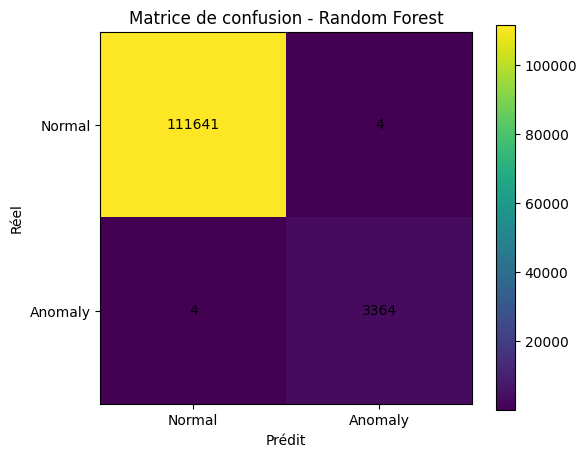


📈 12.5 COURBE ROC


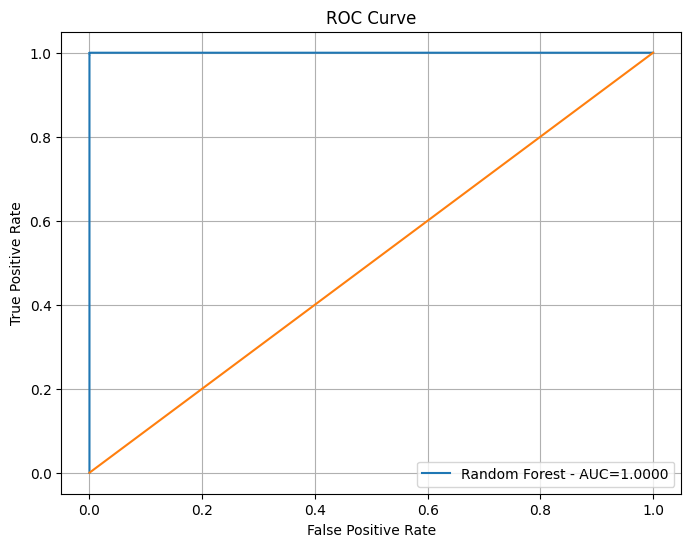


📈 12.6 COURBE PRECISION-RECALL


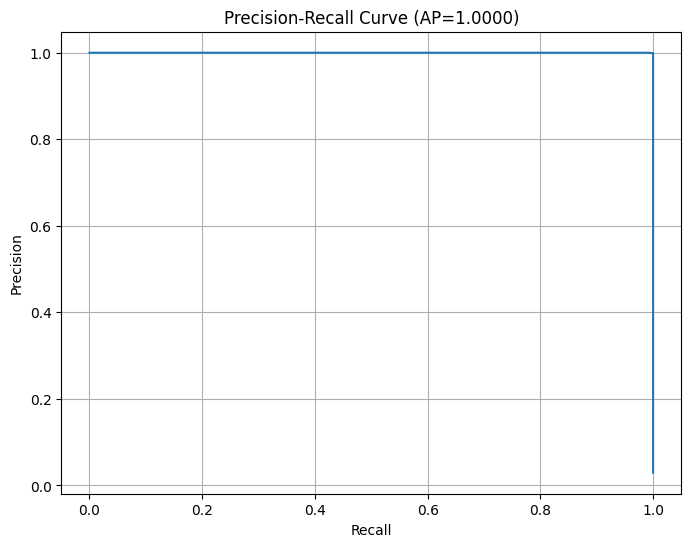


RÉSUMÉ FINAL DU MODÈLE RANDOM FOREST

Modèle : Random Forest
Arbres : 300

Accuracy  : 0.9999
Precision : 0.9988
Recall    : 0.9988
F1-score  : 0.9988
ROC-AUC   : 1.0000

Nombre total tests : 115,013
Anomalies réelles  : 3,368
Anomalies détectées: 3,368

✅ ÉVALUATION TERMINÉE


In [66]:
# ============================================================
# PARTIE 12: ÉVALUATION DU MODÈLE RANDOM FOREST
# ============================================================
# ============================================================
# IMPORTS POUR L'ÉVALUATION
# ============================================================

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    classification_report,
    confusion_matrix,
    roc_curve,
    precision_recall_curve
)

import matplotlib.pyplot as plt

print("✅ Imports d'évaluation chargés")
print("\n" + "=" * 70)
print("PARTIE 12: ÉVALUATION DU MODÈLE RANDOM FOREST")
print("=" * 70)


# ============================================================
# 12.1 Calcul des métriques principales
# ============================================================

print("\n📊 12.1 MÉTRIQUES PRINCIPALES")

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

# Probabilité d'être une anomalie
y_proba_anomaly = y_proba[:, 1]

roc_auc = roc_auc_score(y_test, y_proba_anomaly)
average_precision = average_precision_score(y_test, y_proba_anomaly)


print(f"""
Accuracy  : {accuracy:.4f}
Precision : {precision:.4f}
Recall    : {recall:.4f}
F1-score  : {f1:.4f}
ROC-AUC   : {roc_auc:.4f}
AP Score  : {average_precision:.4f}
""")


# ============================================================
# 12.2 Rapport détaillé
# ============================================================

print("\n📄 12.2 RAPPORT DE CLASSIFICATION")

print(
    classification_report(
        y_test,
        y_pred,
        target_names=["Normal", "Anomaly"],
        digits=4
    )
)


# ============================================================
# 12.3 Matrice de confusion
# ============================================================

print("\n📊 12.3 MATRICE DE CONFUSION")

cm = confusion_matrix(y_test, y_pred)

print(cm)


tn, fp, fn, tp = cm.ravel()

print(f"""
Détails :

✅ True Negative (Normal détecté correctement) : {tn:,}

⚠️ False Positive (Fausse alerte)             : {fp:,}

❌ False Negative (Anomalie ratée)             : {fn:,}

✅ True Positive (Anomalie détectée)            : {tp:,}
""")


# ============================================================
# 12.4 Visualisation matrice confusion
# ============================================================

plt.figure(figsize=(6,5))

plt.imshow(cm)

plt.title("Matrice de confusion - Random Forest")
plt.xlabel("Prédit")
plt.ylabel("Réel")

plt.xticks([0,1], ["Normal", "Anomaly"])
plt.yticks([0,1], ["Normal", "Anomaly"])


for i in range(2):
    for j in range(2):
        plt.text(
            j,
            i,
            cm[i,j],
            ha="center",
            va="center"
        )

plt.colorbar()
plt.show()


# ============================================================
# 12.5 Courbe ROC
# ============================================================

print("\n📈 12.5 COURBE ROC")

fpr, tpr, thresholds = roc_curve(
    y_test,
    y_proba_anomaly
)


plt.figure(figsize=(8,6))

plt.plot(
    fpr,
    tpr,
    label=f"Random Forest - AUC={roc_auc:.4f}"
)

plt.plot(
    [0,1],
    [0,1]
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.title("ROC Curve")
plt.legend()
plt.grid()

plt.show()



# ============================================================
# 12.6 Courbe Precision-Recall
# ============================================================

print("\n📈 12.6 COURBE PRECISION-RECALL")

precision_values, recall_values, thresholds = precision_recall_curve(
    y_test,
    y_proba_anomaly
)


plt.figure(figsize=(8,6))

plt.plot(
    recall_values,
    precision_values
)

plt.xlabel("Recall")
plt.ylabel("Precision")

plt.title(
    f"Precision-Recall Curve (AP={average_precision:.4f})"
)

plt.grid()

plt.show()



# ============================================================
# 12.7 Résumé final
# ============================================================

print("\n" + "=" * 70)
print("RÉSUMÉ FINAL DU MODÈLE RANDOM FOREST")
print("=" * 70)

print(f"""
Modèle : Random Forest
Arbres : {len(rf_model.estimators_)}

Accuracy  : {accuracy:.4f}
Precision : {precision:.4f}
Recall    : {recall:.4f}
F1-score  : {f1:.4f}
ROC-AUC   : {roc_auc:.4f}

Nombre total tests : {len(y_test):,}
Anomalies réelles  : {(y_test==1).sum():,}
Anomalies détectées: {(y_pred==1).sum():,}
""")

print("✅ ÉVALUATION TERMINÉE")


PARTIE 13: FEATURE IMPORTANCE - RANDOM FOREST

📊 13.1 Calcul des importances...
Nombre total de features : 64
Somme des importances   : 1.0000

Nombre de noms générés : 64

🔥 TOP 20 FEATURES LES PLUS IMPORTANTES
----------------------------------------------------------------------
   Feature  Importance
  TFIDF_30    0.089036
  TFIDF_22    0.073290
  TFIDF_39    0.065711
  TFIDF_43    0.064429
   TFIDF_9    0.063037
  TFIDF_32    0.046523
Event_ID_6    0.045230
  TFIDF_31    0.032245
  TFIDF_20    0.029914
  TFIDF_12    0.026397
  TFIDF_44    0.022992
  TFIDF_45    0.022596
  TFIDF_15    0.022412
  TFIDF_16    0.022240
  TFIDF_23    0.022043
  TFIDF_42    0.021443
   TFIDF_2    0.018647
  TFIDF_36    0.017316
  TFIDF_47    0.015648
  TFIDF_28    0.012989


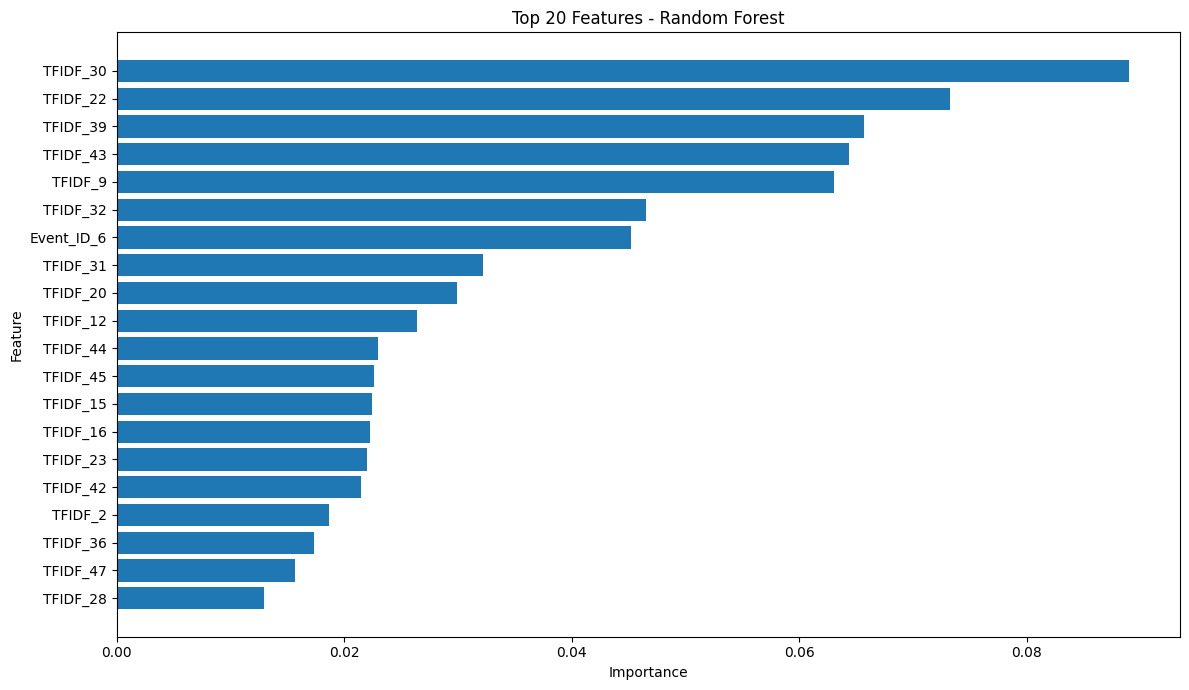


📊 13.5 Importance par groupe de features
          Groupe  Importance
1         TF-IDF    0.888376
0  EventSequence    0.089376
2     Numeriques    0.022248


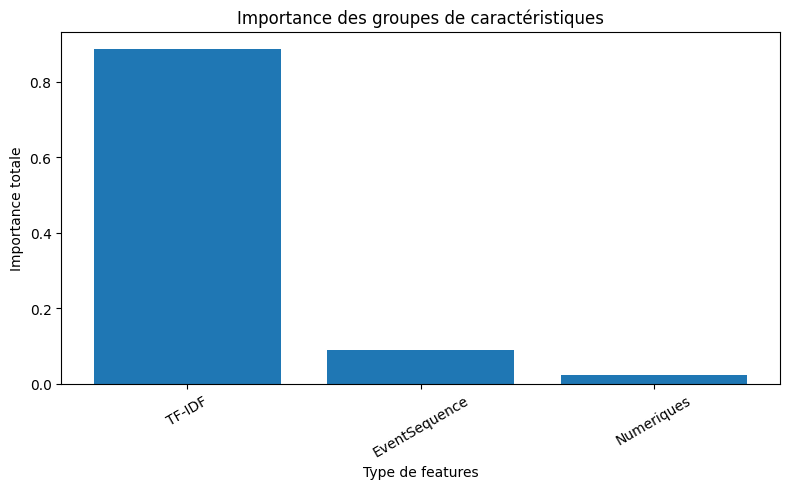


✅ PARTIE 13 TERMINÉE
Analyse des features terminée.


In [67]:
# ============================================================
# PARTIE 13: ANALYSE DE L'IMPORTANCE DES FEATURES
# ============================================================
# Objectif:
# Comprendre quelles caractéristiques influencent la détection
# des anomalies par Random Forest
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


print("\n" + "=" * 70)
print("PARTIE 13: FEATURE IMPORTANCE - RANDOM FOREST")
print("=" * 70)


# ============================================================
# 13.1 Récupérer les importances du modèle
# ============================================================

print("\n📊 13.1 Calcul des importances...")


importances = rf_model.feature_importances_


print(f"Nombre total de features : {len(importances)}")
print(f"Somme des importances   : {importances.sum():.4f}")


# ============================================================
# 13.2 Créer les noms des features
# ============================================================

feature_names = []


# EventSequence
for i in range(10):
    feature_names.append(f"Event_ID_{i}")


# TF-IDF
for i in range(50):
    feature_names.append(f"TFIDF_{i}")


# Features numériques
feature_names += [
    "NumEvents",
    "Duration",
    "NumINFO",
    "NumWARN"
]


print(f"\nNombre de noms générés : {len(feature_names)}")


# ============================================================
# 13.3 DataFrame importance
# ============================================================

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
})


importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)


print("\n🔥 TOP 20 FEATURES LES PLUS IMPORTANTES")
print("-"*70)

print(
    importance_df.head(20).to_string(index=False)
)


# ============================================================
# 13.4 Visualisation Top 20
# ============================================================

plt.figure(figsize=(12,7))

top20 = importance_df.head(20)

plt.barh(
    top20["Feature"][::-1],
    top20["Importance"][::-1]
)

plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title(
    "Top 20 Features - Random Forest"
)

plt.tight_layout()
plt.show()



# ============================================================
# 13.5 Importance par catégorie
# ============================================================

print("\n📊 13.5 Importance par groupe de features")


groups = {
    "EventSequence": importance_df[
        importance_df["Feature"].str.startswith("Event_ID")
    ]["Importance"].sum(),

    "TF-IDF": importance_df[
        importance_df["Feature"].str.startswith("TFIDF")
    ]["Importance"].sum(),

    "Numeriques": importance_df[
        importance_df["Feature"].isin(
            [
                "NumEvents",
                "Duration",
                "NumINFO",
                "NumWARN"
            ]
        )
    ]["Importance"].sum()
}


group_df = pd.DataFrame(
    list(groups.items()),
    columns=["Groupe", "Importance"]
)


group_df = group_df.sort_values(
    "Importance",
    ascending=False
)


print(group_df)



# ============================================================
# 13.6 Graphe par groupe
# ============================================================

plt.figure(figsize=(8,5))

plt.bar(
    group_df["Groupe"],
    group_df["Importance"]
)

plt.xlabel("Type de features")
plt.ylabel("Importance totale")
plt.title(
    "Importance des groupes de caractéristiques"
)

plt.xticks(rotation=30)
plt.tight_layout()

plt.show()


print("\n✅ PARTIE 13 TERMINÉE")
print("Analyse des features terminée.")